# Selecting Recommender Systems When Fairness Rankings Are Unstable
### Phantom Troupe Project 9, revised empirical protocol

Original investigators: Tony Nicholas Panneer Jesuraja and Parvesh Kumar. Based on the archived analysis [10.5281/zenodo.24093518](https://doi.org/10.5281/zenodo.24093518). This revision was designed after inspection of the archived test outcomes. Interpret the new comparisons as exploratory and conditional on these datasets, cohorts and model families. The within-user 1M protocol is a sensitivity analysis on related data. Last.fm uses first observed user–artist tagging events, with tag calibration and item exposure as its scope.

**Kaggle settings.** Import this notebook, select CPU (accelerator **None**), attach the official `ml-100k.zip`, `ml-1m.zip` and `hetrec2011-lastfm-2k.zip` through Add Input, and use **Save Version → Save & Run All**. MovieLens extracted distributions and extracted Kaggle Last.fm files are supported. Internet can be off with all inputs attached. With Internet on, a missing Last.fm ZIP can fall back to the official download. Retrieve the final ZIP from Output. The full run's wall time depends on the Kaggle CPU. The synthetic `PROJECT9_MODE=smoke` path exercises the pipeline with smaller settings and produces clearly marked test outputs.

Provider pages: [MovieLens](https://grouplens.org/datasets/movielens/) and [HetRec 2011](https://grouplens.org/datasets/hetrec-2011/). Consult the dataset READMEs for terms and attribution. The exports contain aggregate evaluation outputs, provenance and settings.

## Research questions and methodology

| Research question | Analysis |
| --- | --- |
| RQ1 — Objective disagreement | Among validation-relevance-eligible candidates, how often do demographic utility parity, calibration and exposure favour different choices? Calculate point winner sets, conditional paired bootstrap agreement, winner support and within-objective ordering retention. |
| RQ2 — Uncertainty and abstention | Which apparent gains survive simultaneous uncertainty assessment, and why does the shortlist abstain? Cover the planned base/reranker family, record later sign reversal and separate missing objectives, insufficient complete draws and cutoff-driven abstention. |
| RQ3 — Shortlist trade-offs | How do bootstrap shortlist size, stability, empty decisions and later quality compare with point Pareto, single-objective winners, relevance and size-matched controls? Use paired nested audits and later quality in each audit's frozen validation-eligible pool. |
| RQ4 — Evaluation sensitivity | How do group coverage and candidate depth affect estimability and conclusions from RQ1–RQ3? Report observed and eligible group counts and compare the 50, 100 and 200 candidate runs on common users, fitted models, score scaling and random draws. |
| RQ5 — Scope of transfer | Which selection patterns recur under within-user MovieLens 1M chronology or Last.fm tagging? Run a common calibration/exposure comparison at depth 100 and report the applicable three-objective MovieLens comparison as a separate target. |

1. Verify official release counts and hash inputs. Use the chronological 70/15/15 global split for 100K, the fixed 3,000-user 1M sample and Last.fm. Use a 70/15/15 within-user split on the full 1M release for the sensitivity case. Timestamp ties follow the earlier window at each cutoff. MovieLens positives are ratings ≥4. Last.fm positives are observed first artist-tagging events within the training-defined catalogue. Use only training history/catalogue for fit, and exclude previously seen items. Audit cohorts require ≥5 training interactions, a positive training history and an eligible held-out positive.
2. Fit popularity, item KNN and explicit matrix factorization, tuning only on validation users reserved by a stable hash. Freeze fitted models. Keep the three original fitting seeds and four reranking weights (0, 0.1, 0.3, 0.5). Rerank for top 10, fixing the score transform to the reference candidate pool at depth 100, with the same nested ranking prefixes for all depths. The transform is affine and deeper items may receive a relevance score below zero.
3. Screen by validation NDCG@10 within 2% of the best configuration, relative to that best score. Lower is better on the maximum marginal age/gender NDCG range, mean discounted genre/tag JSD, and discounted exposure Gini across the training catalogue, including unseen exposure coordinates. Exposure concentration and calibration are proxies with distinct meanings. Use 1,000 common user bootstrap draws for full-cohort diagnostics. Preserve ties in objective winner sets, and count pairwise overlap among jointly estimable draws. Restrict selector comparisons to the validation-eligible set for the relevant full or outer audit.
4. Estimate all planned contrasts jointly at overall alpha 0.05 across protocol, seed, depth and period. Apply a Bonferroni allocation over families. Within each family, use paired bounded-difference Hoeffding intervals for mean calibration contrasts. Use simultaneous bounded-coordinate envelopes propagated to demographic range and exposure Gini. These fixed-model intervals assume independently sampled eligible users and can be very wide. Record effect sizes, endpoints and denominators. The empirical 80% nondominance frequency is a stability statistic. A later estimated sign reversal and a sign reversal supported in both periods are distinct.
5. For each setting, draw 24 paired outer audits (sample size equal to the validation cohort, capped at 512), then 300 inner draws per audit. Require at least 90% complete inner draws. Compare cutoffs of 70%, 80%, and 90%. Assess Jaccard overlap with one-empty pairs counted as zero and both-empty pairs excluded and counted separately. Report later dominated fraction among issued sets and operational later-frontier recall, counting an empty issued set as zero when the frontier is estimable. Report relevance loss relative to the best later NDCG among the frozen validation pool. A later selector is a retrospective diagnostic for the same pool. Fitting seeds, audit pairs and windows give sensitivity evidence rather than independent populations. The reduced nested budget compared with the archived run makes the depth comparison tractable on CPU and introduces Monte Carlo variation near cutoffs.
6. Compare group presence with the original and gender-only definitions for the estimability analysis, preserving small group counts and thresholds. Pair the full-cohort ranking diagnostics and the outer selector audits across depths. Use the same family construction for the interval comparison. The frozen validation pool is defined separately at each depth. Use the shared two-objective analysis for transfer. Distinguish the full 1M protocol's change in target population from independent evidence on Last.fm. The adapted DPFR experiment and preference-drift analyses remain documented in the linked archive. Revised selector comparisons use the controls specified in RQ3.

### Planned exhibits

| Question | Table 1 | Table 2 | Figure 1 | Figure 2 |
| --- | --- | --- | --- | --- |
| RQ1 | Eligibility and point winners | Winner support and pairwise ordering retention | Objective agreement heatmaps | Leading configurations' winner support |
| RQ2 | Paired contrasts and intervals | Evidence and later reversal denominators | Evidence across objectives | Selection and abstention by cutoff |
| RQ3 | Selector scorecard | Paired differences versus controls | Stability against shortlist size | Later frontier recall versus dominated share |
| RQ4 | Group coverage and exclusions | Paired depth sensitivity across RQ1–RQ3 | Group completeness by definition | Candidate recall versus depth |
| RQ5 | Protocol and objective scope | Aligned selector outcomes | Common objective agreement | Later overlap and frontier coverage |

The result ZIP contains 10 PDF figures and 10 CSV tables for these exhibits, along with supporting diagnostic CSVs and a checksum manifest.

The supplementary depth diagnostic records counts of identical ordered top-10 lists, order-only changes and item changes. Its two aggregate CSVs appear in the same ZIP under `diagnostics/`.


In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "1"

import hashlib, io, json, platform, time, zipfile
from collections import defaultdict
from dataclasses import dataclass, asdict
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, FileLink, Markdown
from threadpoolctl import threadpool_limits

MODE = os.environ.get("PROJECT9_MODE", "full")
if MODE not in {"full", "smoke"}:
    raise ValueError("PROJECT9_MODE must be full or smoke.")
try:
    import numba
    from numba import njit
except ImportError:
    if MODE == "full":
        raise RuntimeError("Numba is required for the full CPU analysis. Use the standard Kaggle Python image.")
    numba = None
    def njit(*args, **kwargs):
        return args[0] if args and callable(args[0]) else lambda fn: fn

@dataclass(frozen=True)
class Settings:
    datasets: tuple = ("100k", "1m")
    seeds: tuple = (20261101, 20261102, 20261103)
    sample_seed: int = 20261101
    max_users_1m: int = 3000
    ks: tuple = (10,)
    depths: tuple = (50, 100, 200)
    retrieve: int = 200
    primary_depth: int = 100
    lambdas: tuple = (0.0, 0.1, 0.3, 0.5)
    relevance_tolerance: float = 0.02
    support: float = 0.8
    thresholds: tuple = (0.7, 0.8, 0.9)
    min_train: int = 5
    min_cell: int = 50
    alpha: float = 0.05
    n_boot: int = 1000
    outer_audits: int = 24
    inner_draws: int = 300
    outer_audit_cap: int = 512
    bootstrap_batch: int = 24
    mf_ranks: tuple = (16, 32)
    mf_penalties: tuple = (0.01, 0.1)
    mf_epochs: int = 20
    mf_lr: float = 0.005
    knn_neighbours: int = 50
    lastfm_catalogue: int = 1000

C = Settings() if MODE == "full" else Settings(
    seeds=(20261101,), depths=(12, 20, 30), retrieve=30, primary_depth=20,
    n_boot=30, outer_audits=4, inner_draws=15, mf_ranks=(4,), mf_penalties=(0.1,),
    mf_epochs=2, min_cell=5,
)
WORK = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
ROOT = WORK / f"Project9_{MODE}_{time.strftime('%Y%m%dT%H%M%SZ', time.gmtime())}_{os.urandom(3).hex()}"
for sub in ("figures", "tables", "diagnostics", "manifest"):
    (ROOT / sub).mkdir(parents=True)
START = time.perf_counter()
plt.rcParams.update({"figure.dpi": 115, "pdf.fonttype": 42, "font.size": 9,
                     "axes.spines.right": False, "axes.spines.top": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.2})
EXHIBITS = []
THREAD_GUARD = threadpool_limits(limits=1)

def seed_for(*parts):
    return int(hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()[:8], 16)

def write_json(name, obj):
    (ROOT / "manifest" / f"{name}.json").write_text(json.dumps(obj, indent=2, default=str))

def table(df, name):
    df = pd.DataFrame(df)
    df.to_csv(ROOT / "diagnostics" / f"{name}.csv", index=False)
    return df

def show_table(df, name, title, preview=25):
    path = ROOT / "tables" / f"{name}.csv"
    df.to_csv(path, index=False)
    EXHIBITS.append((name, "CSV", title, str(path.relative_to(ROOT))))
    display(Markdown(f"**{title}** · {len(df):,} rows (first {min(preview, len(df))} shown)"))
    display(df.head(preview).round(5))
    display(FileLink(os.path.relpath(path, Path.cwd())))

def show_figure(fig, name, title):
    path = ROOT / "figures" / f"{name}.pdf"
    if MODE == "smoke":
        fig.text(0.99, 0.005, "Synthetic smoke test", ha="right", color="#9c312b")
    fig.savefig(path, bbox_inches="tight")
    EXHIBITS.append((name, "PDF", title, str(path.relative_to(ROOT))))
    display(Markdown(f"**{title}**"))
    plt.show()
    plt.close(fig)

write_json("configuration", dict(mode=MODE, settings=asdict(C),
    revised_after_prior_test_inspection=True, archived_doi="10.5281/zenodo.24093518",
    versions=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                  scipy=scipy.__version__, matplotlib=matplotlib.__version__,
                  numba=getattr(numba, "__version__", None))))

## 1. Load and audit the releases

In [2]:
SEARCH_ROOTS=[Path("/kaggle/input"),Path.cwd()/"upload",Path.cwd()]
def locate(tag):
    stem="ml-"+tag
    for base in SEARCH_ROOTS:
        if not base.exists(): continue
        paths=sorted(base.rglob(stem+".zip"))
        if paths: return paths[0]
        names="ratings.dat" if tag=="1m" else "u.data"
        paths=sorted(base.rglob(names))
        if paths: return paths[0].parent
    raise FileNotFoundError(f"Attach {stem}.zip or its extracted directory as a Kaggle input.")
def load_release(tag):
    path=locate(tag);prefix="ml-"+tag+"/"
    if path.is_file():
        archive=zipfile.ZipFile(path)
        def read(name): return archive.read(prefix+name)
        digest=hashlib.sha256(path.read_bytes()).hexdigest()
    else:
        def read(name):return (path/name).read_bytes()
        digest=hashlib.sha256(b''.join((p.name.encode()+hashlib.sha256(p.read_bytes()).digest()) for p in sorted(path.iterdir()) if p.is_file())).hexdigest()
    if tag=="1m":
        ratings=pd.read_csv(io.BytesIO(read("ratings.dat")),sep="::",engine="python",
                            names=["uid","iid","rating","timestamp"])
        users=pd.read_csv(io.BytesIO(read("users.dat")),sep="::",engine="python",
                          names=["uid","gender","age","occupation","zip"])
        movies=pd.read_csv(io.BytesIO(read("movies.dat")),sep="::",engine="python",
                           encoding="latin1",names=["iid","title","genres"])
        movies["genres"]=movies.genres.str.split("|")
        readme=read("README").decode("latin1")
        expected=(1000209,6040,3706)
    else:
        ratings=pd.read_csv(io.BytesIO(read("u.data")),sep="\t" if False else "	",
                            names=["uid","iid","rating","timestamp"])
        users=pd.read_csv(io.BytesIO(read("u.user")),sep="|",encoding="latin1",
                          names=["uid","age_raw","gender","occupation","zip"])
        users["age"]=pd.cut(users.age_raw,[-np.inf,17,24,34,44,49,55,np.inf],
                            labels=[1,18,25,35,45,50,56]).astype(int)
        genres=[line.split("|")[0] for line in read("u.genre").decode("latin1").splitlines() if line.strip()]
        raw=pd.read_csv(io.BytesIO(read("u.item")),sep="|",encoding="latin1",header=None)
        movies=raw.iloc[:,:2].copy();movies.columns=["iid","title"]
        movies["genres"]=[[genres[j] for j,v in enumerate(row[5:]) if int(v)==1] for row in raw.values]
        readme=read("README").decode("latin1")
        expected=(100000,943,1682)
    assert (len(ratings),ratings.uid.nunique(),ratings.iid.nunique())==expected
    assert ratings.rating.between(1,5).all()
    assert not ratings.duplicated(["uid","iid"]).any()
    users=users[["uid","gender","age"]].copy()
    assert ratings.uid.isin(users.uid).all() and ratings.iid.isin(movies.iid).all()
    if path.is_file():archive.close()
    return {"tag":tag,"ratings":ratings,"users":users,"movies":movies,
            "provenance":{"input":str(path),"sha256":digest,"counts":expected,"README":readme}}

# RQ1–RQ5: a denser movie protocol plus a separate, partially applicable music-domain check.
import urllib.request

def lastfm_release():
    paths=[]
    for base in SEARCH_ROOTS:
        if base.exists():paths+=list(base.rglob('hetrec2011-lastfm-2k.zip'))
    if paths:path=sorted(set(paths))[0]
    else:
        path=WORK/'hetrec2011-lastfm-2k.zip'
        extracted=sorted(Path('/kaggle/input').rglob('user_taggedartists-timestamps.dat'))
        if len(extracted)>1:raise RuntimeError('Multiple Last.fm copies attached; keep one.')
        if extracted:
            temporary=path.with_suffix('.tmp')
            with zipfile.ZipFile(temporary,'w',compression=zipfile.ZIP_DEFLATED) as bundle:
                for member in sorted(extracted[0].parent.iterdir()):
                    if member.is_file() and (member.suffix.lower()=='.dat' or 'readme' in member.name.lower()):
                        bundle.write(member,arcname=member.name)
            with zipfile.ZipFile(temporary) as bundle:assert bundle.testzip() is None
            os.replace(temporary,path)
        elif not path.exists():
            try:
                with urllib.request.urlopen('https://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-2k.zip',timeout=90) as response:
                    data=response.read()
                temporary=path.with_suffix('.tmp');temporary.write_bytes(data)
                with zipfile.ZipFile(temporary) as bundle:assert bundle.testzip() is None
                os.replace(temporary,path)
            except Exception as exc:raise RuntimeError('Attach official Last.fm ZIP/extracted files or enable Internet.') from exc
    with zipfile.ZipFile(path) as archive:
        def raw(stem):
            name=next(x for x in archive.namelist() if Path(x).name==stem)
            return archive.read(name)
        events=pd.read_csv(io.BytesIO(raw('user_taggedartists-timestamps.dat')),sep='\t')
        assert {'userID','artistID','tagID','timestamp'}<=set(events.columns)
        events['timestamp']=(events.timestamp//1000).astype(np.int64)
        ratings=events.groupby(['userID','artistID'],as_index=False).timestamp.min()
        ratings.columns=['uid','iid','timestamp'];ratings['rating']=5
        bounds=np.quantile(ratings.timestamp,[.70,.85],method='nearest').astype(np.int64)
        tr=ratings[ratings.timestamp<=bounds[0]]
        top=tr.groupby('iid').uid.nunique().sort_values(ascending=False,kind='stable').head(C.lastfm_catalogue).index
        # Tag vocabulary and artist tags use training-time annotations only.
        annotations=events[(events.timestamp<=bounds[0])&events.artistID.isin(top)]
        vocab=set(annotations.tagID.value_counts().head(64).index)
        mapping=annotations.groupby('artistID').tagID.apply(lambda s:sorted(set('tag_'+str(x) if x in vocab else 'other_tag' for x in s)))
        movies=pd.DataFrame({'iid':sorted(top)})
        movies['title']=movies.iid.astype(str);movies['genres']=movies.iid.map(mapping).apply(lambda x:x if isinstance(x,list) and x else ['unannotated'])
        ratings=ratings[ratings.iid.isin(top)].copy()
        users=pd.DataFrame({'uid':sorted(ratings.uid.unique())});users['gender']=None;users['age']=np.nan
        readmes=[x for x in archive.namelist() if 'readme' in Path(x).name.lower()]
        readme=archive.read(readmes[0]).decode('latin1') if readmes else 'See official GroupLens HetRec 2011 documentation.'
    provenance=dict(input=str(path),sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
        source='https://grouplens.org/datasets/hetrec-2011/',task='first observed user–artist tagging interaction recommendation',
        scope='tag-distribution calibration and item exposure only; tags are not asserted to be genres',
        demographics='not supplied; no demographic attributes are inferred or synthesized',README=readme)
    write_json('provenance_lastfm_tag',dict(provenance,training_tag_cutoff=int(bounds[0]),tag_vocabulary_size=len(vocab),catalogue_size=len(top)))
    return dict(tag='lastfm_tag',ratings=ratings,users=users,movies=movies,provenance=provenance,fixed_bounds=bounds)


def synthetic_release(tag):
    rng = np.random.default_rng(seed_for("fixture", tag))
    n_users, n_items = 125, 170
    rows = []
    for uid in range(n_users):
        ids = rng.choice(n_items, 30, replace=False)
        timestamps = rng.choice(np.arange(2000), 30, replace=False)
        for item, stamp in zip(ids, timestamps):
            rows.append((uid, item, int(rng.integers(3, 6)), int(stamp)))
    ratings = pd.DataFrame(rows, columns=["uid", "iid", "rating", "timestamp"])
    users = pd.DataFrame(dict(uid=range(n_users), gender=np.where(np.arange(n_users) % 2, "F", "M"),
                              age=np.resize([1, 18, 25, 35, 45, 50, 56], n_users)))
    if tag == "lastfm_tag":
        users["age"] = np.nan
        users["gender"] = None
        ratings["rating"] = 5
    if tag == "100k":
        # Exercise objective unavailability and missing test groups.
        users["age"] = 25
    movies = pd.DataFrame(dict(iid=range(n_items), title=[f"Item {i}" for i in range(n_items)],
                               genres=[[f"F{i % 5}"] for i in range(n_items)]))
    return dict(tag=tag, ratings=ratings, users=users, movies=movies,
                provenance=dict(sha256="synthetic", counts=(len(rows), n_users, n_items)))

if MODE == "smoke":
    RELEASES = {tag: synthetic_release(tag) for tag in C.datasets}
else:
    RELEASES = {tag: load_release(tag) for tag in C.datasets}
for tag, release in RELEASES.items():
    write_json("provenance_" + tag, release["provenance"])

In [3]:
def prepare(r):
    full=r["ratings"]
    dense=r['tag']=='1m_userchron'
    bounds=np.asarray(r.get('fixed_bounds',np.quantile(full.timestamp,[.70,.85],method='nearest')),dtype=np.int64)
    chosen=np.sort(full.uid.unique())
    if r["tag"]=="1m" and len(chosen)>C.max_users_1m:
        chosen=np.sort(np.random.default_rng(C.sample_seed).choice(chosen,C.max_users_1m,replace=False))
    events=full[full.uid.isin(chosen)].copy()
    uid={u:i for i,u in enumerate(chosen)}
    if dense:
        q=events.groupby('uid').timestamp
        lower=events.uid.map(q.quantile(.70,interpolation='nearest'))
        upper=events.uid.map(q.quantile(.85,interpolation='nearest'))
        train=events[events.timestamp<=lower].copy()
        val=events[(events.timestamp>lower)&(events.timestamp<=upper)].copy()
        test=events[events.timestamp>upper].copy()
    else:
        train=events[events.timestamp<=bounds[0]].copy()
        val=events[(events.timestamp>bounds[0])&(events.timestamp<=bounds[1])].copy()
        test=events[events.timestamp>bounds[1]].copy()
    catalog=np.sort(train.iid.unique());iid={v:i for i,v in enumerate(catalog)}
    for f in [train,val,test]:
        f["u"]=f.uid.map(uid);f["i"]=f.iid.map(iid).fillna(-1).astype(int)
    U,I=len(chosen),len(catalog)
    X=sparse.csr_matrix((train.rating.to_numpy(np.float32),(train.u,train.i)),shape=(U,I))
    P=X.copy();P.data=(P.data>=4).astype(np.float32);P.eliminate_zeros()
    meta=r["users"].set_index("uid").loc[chosen].reset_index(drop=True)
    meta["activity"]=np.diff(X.indptr)
    vocab=sorted({g for gs in r["movies"].genres for g in gs})
    gm=np.zeros((I,len(vocab)),np.float32);gi={g:j for j,g in enumerate(vocab)}
    mov=r["movies"].set_index("iid")
    for i,item in enumerate(catalog):
        gs=mov.loc[item,"genres"] or ["unknown"]
        for g in gs:gm[i,gi[g]]=1/len(gs)
    hist=np.asarray(P@gm);hist/=np.maximum(hist.sum(1,keepdims=True),1)
    seen=[set(X.indices[X.indptr[u]:X.indptr[u+1]]) for u in range(U)]
    result=dict(tag=r["tag"],train=train,val=val,test=test,meta=meta,X=X,P=P,G=gm,
                profiles=hist,seen=seen,U=U,I=I,catalog=catalog,bounds=bounds,vocab=vocab)
    result['tuning_users']={u for u,original_uid in enumerate(chosen) if seed_for('tuning_user',int(original_uid))%5==0}
    result['evaluation_users']=set(range(U))-result['tuning_users']
    result['split_protocol']='within_user_chronological' if dense else 'global_chronological'
    return result
DATA={t:prepare(r) for t,r in RELEASES.items()}
table([{"dataset":t,"window":w,"events":len(d[w]),"users":d[w].u.nunique(),
        "unseen_training_items":int((d[w].i<0).sum()),
        "start_utc":pd.to_datetime(d[w].timestamp.min(),unit="s",utc=True),
        "end_utc":pd.to_datetime(d[w].timestamp.max(),unit="s",utc=True)}
       for t,d in DATA.items() for w in ["train","val","test"]],"chronological_split_audit")
def cohort(d,window):
    frame=d[window];seen=[s.copy() for s in d["seen"]]
    if window=="test":
        for u,i in d["val"][["u","i"]].itertuples(index=False,name=None):
            if i>=0:seen[u].add(i)
    observed=np.sort(frame.u.unique());positives=defaultdict(set)
    for u,i,rating in frame[["u","i","rating"]].itertuples(index=False,name=None):
        if rating>=4 and i>=0 and i not in seen[u]:positives[u].add(i)
    counts=np.diff(d["X"].indptr);liked=np.diff(d["P"].indptr)
    rows=[];eligible=[]
    for u in observed:
        reason=("No training history" if counts[u]==0 else
                "Below minimum history" if counts[u]<C.min_train else
                "No liked training item" if liked[u]==0 else
                "No eligible positive" if not positives[u] else "Eligible")
        rows.append({"u":u,"reason":reason})
        if reason=="Eligible":eligible.append(u)
    return dict(users=np.array(eligible,dtype=int),positive=positives,seen=seen,
                audit=pd.DataFrame(rows))
cohort_raw=cohort

def cohort(d,window):
    original='val' if window=='tune' else window
    co=cohort_raw(d,original)
    keep=d['tuning_users'] if window=='tune' else d['evaluation_users']
    co['users']=np.array([u for u in co['users'] if u in keep],dtype=int)
    audit=co['audit'].copy()
    audit.loc[(audit.reason=='Eligible')&(~audit.u.isin(keep)),'reason']='Reserved for other user role'
    co['audit']=audit
    return co


DATA["1m_userchron"] = prepare(dict(RELEASES["1m"], tag="1m_userchron"))
DATA["lastfm_tag"] = prepare(synthetic_release("lastfm_tag") if MODE == "smoke" else lastfm_release())
PROTOCOLS = list(DATA)
GLOBAL = list(C.datasets)
OBJECTIVES = {1: "Group gap", 2: "Calibration JSD", 3: "Exposure Gini"}
COHORTS = {}
scope_rows, group_rows = [], []
for tag, d in DATA.items():
    assert not d["tuning_users"] & d["evaluation_users"]
    if tag == "1m_userchron":
        for earlier, later in (("train", "val"), ("val", "test"), ("train", "test")):
            pair = pd.concat([d[earlier].groupby("u").timestamp.max(),
                              d[later].groupby("u").timestamp.min()], axis=1).dropna()
            assert (pair.iloc[:, 0] < pair.iloc[:, 1]).all()
    else:
        assert d["train"].timestamp.max() < d["val"].timestamp.min()
        assert d["val"].timestamp.max() < d["test"].timestamp.min()
    for part in ("tune", "val", "test"):
        co = COHORTS[tag, part] = cohort(d, part)
        if len(co["users"]) < 2:
            raise ValueError(f"{tag}/{part}: fewer than two eligible users. Check the official input release.")
        frame = d["val" if part == "tune" else part]
        scope_rows.append(dict(protocol=tag, split=d["split_protocol"], window=part,
            observed_users=frame.u.nunique(), eligible_users=len(co["users"]),
            events=len(frame), unseen_catalogue_events=int((frame.i < 0).sum()),
            catalogue=d["I"], start_utc=pd.to_datetime(frame.timestamp.min(), unit="s", utc=True),
            end_utc=pd.to_datetime(frame.timestamp.max(), unit="s", utc=True),
            demographic_gap_available_in_scope=tag != "lastfm_tag",
            calibration_feature="artist tags" if tag == "lastfm_tag" else "movie genres"))
        if tag == "lastfm_tag" or part == "tune":
            continue
        meta = d["meta"]
        observed = meta.iloc[frame.u.unique()]
        eligible = meta.iloc[co["users"]]
        for attr, levels in (("gender", ["F", "M"]), ("age", [1, 18, 25, 35, 45, 50, 56]),
                             ("age_by_gender", [(age, sex) for age in [1,18,25,35,45,50,56] for sex in ["F","M"]])):
            for level in levels:
                def count_group(frame):
                    mask = ((frame.age == level[0]) & (frame.gender == level[1])
                            if attr == "age_by_gender" else frame[attr] == level)
                    return int(mask.sum())
                obs, n = count_group(observed), count_group(eligible)
                role_col = co["audit"].reason.eq("Reserved for other user role")
                reserved = count_group(meta.iloc[co["audit"].loc[role_col, "u"].to_numpy(int)])
                group_rows.append(dict(protocol=tag, window=part, attribute=attr, group=str(level),
                    observed_users=obs, eligible_users=n, otherwise_eligible_reserved_for_tuning=reserved,
                    inclusion_rate=n/obs if obs else np.nan, below_reporting_threshold=n<C.min_cell))
SCOPE = pd.DataFrame(scope_rows)
GROUP = pd.DataFrame(group_rows)

## 2. Fit the models and construct paired audits

In [4]:
DISCOUNT=1/np.log2(np.arange(1,C.retrieve+1)+1)
def jsd(p,q):
    p=np.asarray(p,float);q=np.asarray(q,float);m=(p+q)/2
    a=np.zeros_like(m);b=np.zeros_like(m)
    np.divide(p,m,out=a,where=m>0);np.divide(q,m,out=b,where=m>0)
    with np.errstate(divide="ignore",invalid="ignore"):
        v=.5*np.sum(np.where(p>0,p*np.log2(np.maximum(a,1e-300)),0),axis=-1)
        v+=.5*np.sum(np.where(q>0,q*np.log2(np.maximum(b,1e-300)),0),axis=-1)
    return np.maximum(v,0)
def gini(e):
    e=np.asarray(e,float);v=np.sort(e,axis=-1);n=v.shape[-1]
    den=n*v.sum(axis=-1)
    return np.divide((v*(2*np.arange(1,n+1)-n-1)).sum(axis=-1),den,
                     out=np.full(np.shape(den),np.nan),where=den>0)
def ndcg_list(items,pos,k):
    hits=np.array([i in pos for i in items[:k]])
    den=DISCOUNT[:min(k,len(pos))].sum()
    return (hits*DISCOUNT[:len(hits)]).sum()/den if den else np.nan
assert np.isclose(jsd([1,0],[0,1]),1)
assert np.isclose(jsd([.5,.5],[.5,.5]),0)
assert np.isclose(gini([1,1,1]),0)
assert np.isclose(gini([3,0,0]),2/3)
assert np.isclose(ndcg_list([1,2],{1,2},2),1)
table(pd.DataFrame({"check":["JSD opposite profiles","JSD identical","Gini equal","Gini concentrated","NDCG perfect"],
                    "status":["passed"]*5}),"metric_checks")
@njit
def sgd_fit(us,it,ratings,U,I,rank,reg,epochs,lr,seed):
    np.random.seed(seed)
    A=np.random.normal(0,.05,(U,rank));B=np.random.normal(0,.05,(I,rank))
    bu=np.zeros(U);bi=np.zeros(I);mean=ratings.mean()
    for epoch in range(epochs):
        for z in np.random.permutation(len(ratings)):
            u=us[z];i=it[z];err=ratings[z]-mean-bu[u]-bi[i]-np.dot(A[u],B[i])
            bu[u]+=lr*(err-reg*bu[u]);bi[i]+=lr*(err-reg*bi[i])
            for f in range(rank):
                a=A[u,f];b=B[i,f]
                A[u,f]+=lr*(err*b-reg*a);B[i,f]+=lr*(err*a-reg*b)
    return A.astype(np.float32),B.astype(np.float32),bu,bi,mean
def mf_fit(d,rank,reg,seed):
    tr=d["train"]
    return sgd_fit(tr.u.to_numpy(np.int64),tr.i.to_numpy(np.int64),tr.rating.to_numpy(float),
                   d["U"],d["I"],rank,reg,C.mf_epochs,C.mf_lr,seed)
def knn_fit(d):
    P=d["P"];norm=np.sqrt(np.asarray(P.power(2).sum(0)).ravel())
    Z=P@sparse.diags(1/np.maximum(norm,1))
    sim=(Z.T@Z).tocsr();sim.setdiag(0);sim.eliminate_zeros()
    rows=[];cols=[];vals=[]
    for i in range(d["I"]):
        st,en=sim.indptr[i:i+2];ids=sim.indices[st:en];v=sim.data[st:en]
        order=np.lexsort((ids,-v))[:C.knn_neighbours]
        rows.extend([i]*len(order));cols.extend(ids[order]);vals.extend(v[order])
    return sparse.csr_matrix((vals,(rows,cols)),shape=sim.shape)
def score_user(d,model,u):
    typ,obj=model
    if typ=="Popularity":return obj.copy()
    if typ=="ItemKNN":return np.asarray((d["P"][u]@obj).toarray()).ravel()
    A,B,bu,bi,mean=obj
    return A[u]@B.T+bu[u]+bi+mean
def retrieve(d,model,co,depth):
    lists=[];scores=[]
    for u in co["users"]:
        s=score_user(d,model,u).astype(float);s[list(co["seen"][u])]=-np.inf
        ids=np.flatnonzero(np.isfinite(s));order=np.lexsort((ids,-s[ids]))[:depth]
        ids=ids[order]
        if len(ids)<depth:raise ValueError(f'Fewer than {depth} unseen train-catalogue items for {d["tag"]} user index {u}.')
        lists.append(ids);scores.append(s[ids])
    return np.asarray(lists),np.asarray(scores)
def rerank(ids,scores,profiles,G,lam,kmax=max(C.ks)):
    if lam==0:return ids[:,:kmax].copy()
    out=np.empty((len(ids),kmax),int)
    for u,(cand,score) in enumerate(zip(ids,scores)):
        rel=score
        mass=np.zeros(G.shape[1]);den=0.;used=np.zeros(len(cand),bool)
        for r in range(kmax):
            q=(mass+DISCOUNT[r]*G[cand])/(den+DISCOUNT[r])
            gain=(1-lam)*rel-lam*jsd(profiles[u][None,:],q)
            gain[used]=-np.inf
            j=np.lexsort((cand,-gain))[0];out[u,r]=cand[j];used[j]=True
            mass+=DISCOUNT[r]*G[cand[j]];den+=DISCOUNT[r]
    return out
def candidate_name(base,lam):return base+"__lambda_"+str(lam)
BASES=["Popularity","ItemKNN","MF"]
NAMES=[candidate_name(b,l) for b in BASES for l in C.lambdas]
PAIRS=[(NAMES.index(candidate_name(b,0.0)),NAMES.index(candidate_name(b,l)))
       for b in BASES for l in C.lambdas if l>0]# RQ1–RQ5 performance helpers: same objectives, draws, seeds and tie-break policy.
from threadpoolctl import threadpool_limits
import pickle

rerank_python_reference=rerank
RERANK_PARITY_CHECKS=set()
@njit(fastmath=False)
def _rerank_compiled(ids,scores,profiles,G,lam,kmax,discount):
    N,T=ids.shape;H=G.shape[1];out=np.empty((N,kmax),np.int64);ambiguous=np.zeros(N,np.bool_)
    for u in range(N):
        
        mass=np.zeros(H);used=np.zeros(T,np.bool_);den=0.
        for rank in range(kmax):
            best=-np.inf;best_item=9223372036854775807;best_j=-1
            for j in range(T):
                if used[j]:continue
                divp=0.;divq=0.
                for h in range(H):
                    p=profiles[u,h];q=(mass[h]+discount[rank]*G[ids[u,j],h])/(den+discount[rank]);m=(p+q)/2
                    if m>0:
                        if p>0:divp+=p*np.log2(max(p/m,1e-300))
                        if q>0:divq+=q*np.log2(max(q/m,1e-300))
                divergence=max(.5*divp+.5*divq,0.)
                value=(1-lam)*scores[u,j]-lam*divergence
                if best_j>=0 and 0<abs(value-best)<1e-11:ambiguous[u]=True
                if value>best or (value==best and ids[u,j]<best_item):
                    best=value;best_item=ids[u,j];best_j=j
            out[u,rank]=best_item;used[best_j]=True
            for h in range(H):mass[h]+=discount[rank]*G[best_item,h]
            den+=discount[rank]
    return out,ambiguous

def rerank(ids,scores,profiles,G,lam,kmax=max(C.ks)):
    if lam==0:return ids[:,:kmax].copy()
    if not np.isfinite(profiles).all():
        raise ValueError('Nonfinite reranking profiles; inspect history eligibility.')
    result,ambiguous=_rerank_compiled(ids,scores,np.asarray(profiles,float),G,lam,kmax,DISCOUNT)
    # Near ties use the exact original NumPy routine, never a changed tolerance.
    for u in np.flatnonzero(ambiguous):
        result[u]=rerank_python_reference(ids[u:u+1],scores[u:u+1],profiles[u:u+1],G,lam,kmax)[0]
    key=(float(lam),int(kmax),G.shape,ids.shape[1])
    if key not in RERANK_PARITY_CHECKS:
        count=min(len(ids),24)
        expected=rerank_python_reference(ids[:count],scores[:count],profiles[:count],G,lam,kmax)
        if not np.array_equal(result[:count],expected):
            raise AssertionError('Compiled/reference reranking mismatch. No results should be interpreted; inspect numerical ties.')
        RERANK_PARITY_CHECKS.add(key)
    return result


@dataclass
class Audit:
    users: np.ndarray
    utility: np.ndarray
    calibration: np.ndarray
    exposure: list
    groups: np.ndarray

def make_audit(d, co, lists):
    users = co["users"]
    discount = DISCOUNT[:10]
    u, cal, exp = [], [], []
    for name in NAMES:
        rows = lists[name]
        assert rows.shape == (len(users), 10) and (np.sort(rows, axis=1)[:, 1:] != np.sort(rows, axis=1)[:, :-1]).all()
        u.append([ndcg_list(row, co["positive"][uid], 10) for uid, row in zip(users, rows)])
        q = (d["G"][rows] * discount[None, :, None]).sum(1) / discount.sum()
        cal.append(jsd(d["profiles"][users], q))
        exp.append(sparse.csr_matrix((np.tile(discount / discount.sum(), len(users)),
                    (np.repeat(np.arange(len(users)), 10), rows.ravel())),
                    shape=(len(users), d["I"])).T.tocsr())
    meta = d["meta"].iloc[users]
    groups = np.asarray([meta.gender.eq(sex).to_numpy() for sex in ["F", "M"]] +
                        [meta.age.eq(age).to_numpy() for age in [1,18,25,35,45,50,56]], dtype=float)
    return Audit(users, np.asarray(u), np.asarray(cal), exp, groups)

def metrics(audit, weights):
    w = np.atleast_2d(weights).astype(float)
    n = w.sum(axis=1)
    scores = np.full((len(w), len(NAMES), 4), np.nan)
    scores[:, :, 0] = (w @ audit.utility.T) / n[:, None]
    scores[:, :, 2] = (w @ audit.calibration.T) / n[:, None]
    counts = w @ audit.groups.T
    means = np.stack([(w @ (audit.utility * group).T) / np.where(counts[:, i:i+1] > 0,
                      counts[:, i:i+1], np.nan) for i, group in enumerate(audit.groups)], axis=-1)
    gap = lambda subset: subset.max(-1) - subset.min(-1)
    scores[:, :, 1] = np.maximum(gap(means[:, :, :2]), gap(means[:, :, 2:]))
    for m, matrix in enumerate(audit.exposure):
        scores[:, m, 3] = gini((matrix @ np.ascontiguousarray(w.T)).T)
    return scores

def bootstrap(audit, token, draws, weights=None, sample_size=None):
    n = len(audit.users)
    rng = np.random.default_rng(seed_for(*token))
    p = np.ones(n)/n if weights is None else weights / weights.sum()
    count = n if sample_size is None else sample_size
    out = []
    for start in range(0, draws, C.bootstrap_batch):
        batch = min(C.bootstrap_batch, draws - start)
        out.append(metrics(audit, rng.multinomial(count, p, size=batch)))
    return np.concatenate(out)

def choose_models(d, tag, seed, pop, knn):
    co = COHORTS[tag, "tune"]
    choices = []
    for rank in C.mf_ranks:
        for reg in C.mf_penalties:
            fit = mf_fit(d, rank, reg, seed)
            ids, _ = retrieve(d, ("MF", fit), co, 10)
            score = np.mean([ndcg_list(row, co["positive"][u], 10) for row,u in zip(ids, co["users"])])
            choices.append((score, rank, reg, fit))
    score, rank, reg, fit = min(choices, key=lambda z: (-z[0], z[1], -z[2]))
    write_json(f"{tag}_{seed}_MF", dict(rank=rank, penalty=reg, tuning_ndcg=score,
        grid=[dict(rank=r, penalty=p, tuning_ndcg=s) for s,r,p,_ in choices]))
    return {"Popularity":("Popularity",pop), "ItemKNN":("ItemKNN",knn), "MF":("MF",fit)}

def top10_depth_counts(reference, other):
    """Count changes within aligned rows of two final top-10 arrays."""
    if reference.ndim != 2 or reference.shape[1] != 10 or other.shape != reference.shape:
        raise ValueError("The comparison requires aligned arrays with ten recommendations per user.")
    same_order = (reference == other).all(axis=1)
    same_items = (np.sort(reference, axis=1) == np.sort(other, axis=1)).all(axis=1)
    return dict(users=int(len(reference)), unchanged_top10=int(same_order.sum()),
                order_only_changed=int((same_items & ~same_order).sum()),
                items_changed=int((~same_items).sum()))

def prepare_rankings(d, tag, seed, models, recall_rows, top10_rows):
    result = {}
    depths = C.depths if tag in GLOBAL else (C.primary_depth,)
    for window in ("val", "test"):
        co = COHORTS[tag, window]
        lists = {depth: {} for depth in depths}
        for base, model in models.items():
            ids, raw = retrieve(d, model, co, max(depths))
            anchor = raw[:, :C.primary_depth]
            scores = (raw - anchor.min(axis=1, keepdims=True)) / np.maximum(np.ptp(anchor, axis=1, keepdims=True), 1e-12)
            for depth in depths:
                ranked = ids[:, :depth]
                recall = np.asarray([len(set(row) & co["positive"][u]) / len(co["positive"][u])
                                     for row, u in zip(ranked, co["users"])])
                recall_rows.append(dict(protocol=tag, seed=seed, window=window, depth=depth, model=base,
                    users=len(recall), mean_recall=recall.mean(), zero_recall_rate=np.mean(recall == 0)))
                for lam in C.lambdas:
                    lists[depth][candidate_name(base, lam)] = rerank(
                        ranked, scores[:, :depth], d["profiles"][co["users"]], d["G"], lam)
        if len(depths) > 1:
            # Each depth uses the same ordered cohort and fitted configuration.
            reference_lists = lists[C.primary_depth]
            for depth in depths:
                if depth == C.primary_depth:
                    continue
                for candidate, reference in reference_lists.items():
                    top10_rows.append(dict(
                        protocol=tag, seed=seed, window=window, candidate=candidate,
                        depth=depth, reference_depth=C.primary_depth,
                        **top10_depth_counts(reference, lists[depth][candidate]),
                    ))
        for depth in depths:
            result[depth, window] = make_audit(d, co, lists[depth])
    return result

## 3. Estimate disagreement, uncertainty and later quality

In [5]:
EPS = 1e-12
PAIRED_OBJECTIVES = (2, 3)
ALL_OBJECTIVES = (1, 2, 3)
SINGLE_RULES = {1:"Single gap", 2:"Single calibration", 3:"Single exposure"}

def eligible_ids(point):
    scores = point[:, 0]
    best = scores.max()
    return np.flatnonzero(scores >= (1 - C.relevance_tolerance) * best - EPS) if best > 0 else np.array([], int)

def winner_set(values, ids):
    if not len(ids) or not np.isfinite(values[ids]).all():
        return set()
    return set(ids[np.abs(values[ids] - values[ids].min()) <= EPS])

def pareto_flags(values):
    # Accept either a single objective matrix or a batch of draws.
    x, y = values[..., :, None, :], values[..., None, :, :]
    return ~(((x <= y + EPS).all(axis=-1) & (x < y - EPS).any(axis=-1)).any(axis=-2))

def persistence(point, boot, ids, objectives):
    if not len(ids):
        return np.full(len(ids), np.nan), 0, "No relevance eligible candidate"
    if not np.isfinite(point[ids][:, objectives]).all():
        return np.full(len(ids), np.nan), 0, "Objective unavailable"
    threshold = int(np.ceil(.9 * len(boot)))
    selected = boot[:, ids][:, :, objectives]
    valid = np.isfinite(selected).all(axis=(1,2))
    n = int(valid.sum())
    if n < threshold:
        return np.full(len(ids), np.nan), n, "Insufficient complete draws"
    return pareto_flags(selected[valid]).mean(axis=0), n, "Ready"

def quality(chosen, later, ids, objectives):
    size = len(chosen)
    subset = sorted(chosen)
    best = later[ids, 0].max() if len(ids) else np.nan
    loss = float(np.median(1-later[subset, 0]/best)) if size and best > 0 else np.nan
    values = later[ids][:, objectives]
    assessable = len(ids) > 0 and np.isfinite(values).all()
    frontier = set(ids[pareto_flags(values)]) if assessable else set()
    return dict(size=size, test_frontier_estimable=assessable,
                test_frontier_recall=len(chosen & frontier)/len(frontier) if assessable else np.nan,
                test_dominated=len(chosen - frontier)/size if assessable and size else np.nan,
                median_test_relevance_loss=loss)

def select(point, boot, ids, objectives, key):
    support, complete, reason = persistence(point, boot, ids, objectives)
    chosen = set(ids[support >= C.support])
    status = ("Selected" if chosen else "Threshold abstention") if reason == "Ready" else reason
    results = {"Bootstrap Pareto": chosen}
    values = point[ids][:, objectives]
    results["Point Pareto"] = set(ids[pareto_flags(values)]) if len(ids) and np.isfinite(values).all() else set()
    for j in objectives:
        contenders = winner_set(point[:,j], ids)
        results[SINGLE_RULES[j]] = {min(contenders, key=lambda m:(-point[m,0],m))} if contenders else set()
    ranked = sorted(ids, key=lambda i:(-point[i,0],i))
    results["Top relevance"] = set(ranked[:1])
    n = len(chosen)
    rng = np.random.default_rng(seed_for("size_control", *key))
    # Common random priority over the full candidate universe across depths.
    results["Size-matched random"] = set([i for i in rng.permutation(len(NAMES)) if i in set(ids)][:n])
    results["Size-matched relevance"] = set(ranked[:n])
    return results, support, complete, reason, status

def jaccard(a, b):
    return len(a & b)/len(a | b) if (a or b) else np.nan

def contrast_intervals(audit, point, family_alpha, objectives):
    # Simultaneous coordinate envelope, plus a separately budgeted direct
    # paired bound for calibration differences. Both hold by union bound.
    m, n = audit.utility.shape
    catalogue = audit.exposure[0].shape[0]
    gcount = 9 if 1 in objectives else 0
    coord_alpha = family_alpha / 2
    coordinates = m * (gcount + catalogue)
    radius = lambda count, width=1.: width * np.sqrt(np.log(2*coordinates/coord_alpha)/(2*count)) if count else width
    low, high = np.zeros((m,4)), np.ones((m,4))
    if 1 in objectives:
        group_lo, group_hi = [], []
        for group in audit.groups:
            mask = group.astype(bool)
            count = int(mask.sum())
            mean = audit.utility[:, mask].mean(1) if count else np.full(m, .5)
            group_lo.append(np.clip(mean-radius(count), 0, 1))
            group_hi.append(np.clip(mean+radius(count), 0, 1))
        lo, hi = np.asarray(group_lo).T, np.asarray(group_hi).T
        low[:,1] = np.maximum.reduce([np.zeros(m), lo[:,:2].max(1)-hi[:,:2].min(1), lo[:,2:].max(1)-hi[:,2:].min(1)])
        high[:,1] = np.maximum(hi[:,:2].max(1)-lo[:,:2].min(1), hi[:,2:].max(1)-lo[:,2:].min(1))
    coordinate_span = 1 / DISCOUNT[:10].sum()
    r = radius(n, coordinate_span)
    for i, exp in enumerate(audit.exposure):
        p = np.asarray(exp.sum(axis=1)).ravel() / n
        # Each exposure vector is a probability distribution. Gini changes
        # by at most the L1 distance between two distributions.
        l1 = min(2., np.maximum(np.minimum(p, r), np.minimum(np.maximum(0, coordinate_span-p), r)).sum())
        low[i,3], high[i,3] = max(0.,point[i,3]-l1), min(1-1/catalogue,point[i,3]+l1)
    direct_radius = 2*np.sqrt(np.log(2*len(PAIRS)/(family_alpha/2))/(2*n))
    return low, high, direct_radius

In [6]:
candidate_rows, agreement_rows, support_rows, contrast_rows = [], [], [], []
audit_rows, temporal_rows, threshold_rows, recall_rows, coverage_rows = [], [], [], [], []
family_cells = (len(GLOBAL)*len(C.depths) + len(PROTOCOLS)-len(GLOBAL))*len(C.seeds)*2
family_alpha = C.alpha/family_cells
write_json("inference", dict(overall_alpha=C.alpha, families=family_cells, per_family_alpha=family_alpha,
    allocation="Half to coordinate envelopes for utility gaps and Gini, half to direct paired JSD contrasts",
    target="Fixed-model eligible-user means under independent-user sampling. No retraining uncertainty.",
    state="Exploratory revision after prior result inspection"))

def record_ranking(tag, seed, depth, point, boot, ids, objectives):
    key = dict(protocol=tag, seed=seed, depth=depth)
    winners = {j:winner_set(point[:,j],ids) for j in objectives}
    valid_draws = {j:(np.isfinite(boot[:,ids,j]).all(1) if len(ids) else np.zeros(len(boot),bool)) for j in objectives}
    draw_winners = {j:[winner_set(row[:,j],ids) if ok else set() for row,ok in zip(boot, valid_draws[j])]
                    for j in objectives}
    for c,name in enumerate(NAMES):
        candidate_rows.append(dict(**key, candidate=name, ndcg=point[c,0], group_gap=point[c,1],
            calibration=point[c,2], exposure=point[c,3], eligible=c in ids,
            point_winner_objectives="; ".join(OBJECTIVES[j] for j in objectives if c in winners[j])))
    for a,b in combinations(objectives,2):
        valid = valid_draws[a] & valid_draws[b]
        ov = [bool(left & right) for left,right,ok in zip(draw_winners[a],draw_winners[b],valid) if ok]
        agreement_rows.append(dict(**key, objective_a=OBJECTIVES[a], objective_b=OBJECTIVES[b],
            eligible=len(ids), point_agreement=bool(winners[a]&winners[b]) if winners[a] and winners[b] else np.nan,
            complete_paired_draws=int(valid.sum()), draw_agreement_rate=np.mean(ov) if ov else np.nan))
    for j in objectives:
        pairs = [(a,b) for a,b in combinations(ids,2) if np.isfinite(point[[a,b],j]).all()
                 and abs(point[a,j]-point[b,j]) > EPS]
        sign_retention = [np.mean(np.sign(boot[valid_draws[j],a,j]-boot[valid_draws[j],b,j]) ==
                                  np.sign(point[a,j]-point[b,j]))
                          for a,b in pairs] if valid_draws[j].any() else []
        for c in ids:
            counts = [c in s for s,ok in zip(draw_winners[j],valid_draws[j]) if ok]
            support_rows.append(dict(**key, objective=OBJECTIVES[j],candidate=NAMES[c],
                point_winner=c in winners[j] if winners[j] else np.nan,
                valid_draws=len(counts), winner_support=np.mean(counts) if counts else np.nan,
                nontied_candidate_pairs=len(pairs),
                mean_pair_sign_retention=np.mean(sign_retention) if sign_retention else np.nan))

def record_intervals(tag, seed, depth, val, later, va, te, objectives):
    lo1, hi1, rad1 = contrast_intervals(va,val,family_alpha,objectives)
    lo2, hi2, rad2 = contrast_intervals(te,later,family_alpha,objectives)
    for a,b in PAIRS:
        for j in objectives:
            v, t = val[a,j]-val[b,j], later[a,j]-later[b,j]
            if j == 2:
                vl,vh = max(-1., v-rad1), min(1., v+rad1)
                tl,th = max(-1., t-rad2), min(1., t+rad2)
            else:
                vl,vh = lo1[a,j]-hi1[b,j], hi1[a,j]-lo1[b,j]
                tl,th = lo2[a,j]-hi2[b,j], hi2[a,j]-lo2[b,j]
            status = "Unavailable" if not np.isfinite(v) else ("Supported improvement" if vl > 0 else
                "Supported worsening" if vh < 0 else "Inconclusive")
            reversal = bool(v*t < 0) if np.isfinite(v) and np.isfinite(t) and abs(v)>EPS and abs(t)>EPS else np.nan
            contrast_rows.append(dict(protocol=tag, seed=seed, depth=depth, objective=OBJECTIVES[j],
                base=NAMES[a], reranker=NAMES[b], validation_gain=v, val_low=vl,val_high=vh,
                test_gain=t,test_low=tl,test_high=th, validation_evidence=status,
                apparent_improvement=bool(v>EPS) if np.isfinite(v) else np.nan,
                estimated_sign_reversal=reversal,
                supported_sign_reversal=bool((vl>0 and th<0) or (vh<0 and tl>0)) if np.isfinite(v) and np.isfinite(t) else np.nan))

def record_selectors(tag, seed, depth, va, val, later, full_boot, test_boot, ids, objectives, scope, draw_cache):
    key = dict(protocol=tag, seed=seed, depth=depth, scope=scope)
    original, _, n0, why0, status0 = select(val, full_boot, ids, objectives, (tag, -1))
    later_sets, _, n1, why1, status1 = select(later, test_boot, ids, objectives, (tag, -1))
    for rule, chosen in original.items():
        future = later_sets[rule]
        temporal_rows.append(dict(**key, rule=rule, validation_size=len(chosen), later_size=len(future),
            later_overlap=jaccard(chosen, future), validation_empty=not chosen, later_empty=not future,
            validation_complete_draws=n0,later_complete_draws=n1,
            validation_bootstrap_status=status0,later_bootstrap_status=status1,
            **quality(chosen,later,ids,objectives)))
    size = min(len(va.users),C.outer_audit_cap)
    rng = np.random.default_rng(seed_for("outer",tag))
    for rep in range(C.outer_audits):
        w = rng.multinomial(size,np.ones(len(va.users))/len(va.users))
        if rep not in draw_cache:
            draw_cache[rep] = [metrics(va,w)[0], None]
        p, cached_boot = draw_cache[rep]
        pool = eligible_ids(p)
        # When required groups are absent from the outer audit, inner resampling
        # cannot recover them. The same draw tokens are used across depths.
        if not len(pool) or not np.isfinite(p[pool][:,objectives]).all():
            b = np.full((C.inner_draws,len(NAMES),4),np.nan)
        else:
            if cached_boot is None:
                cached_boot = bootstrap(va,("inner",tag,rep),C.inner_draws,weights=w,sample_size=size)
                draw_cache[rep][1] = cached_boot
            b = cached_boot
        sets, supports, complete, reason, status = select(p,b,pool,objectives,(tag,rep))
        for rule, chosen in sets.items():
            audit_rows.append(dict(**key,audit=rep,audit_sample_size=size,distinct_audit_users=int(np.count_nonzero(w)),
                rule=rule, eligible_count=len(pool), eligible_candidates="|".join(NAMES[i] for i in pool), selected="|".join(NAMES[i] for i in sorted(chosen)),
                bootstrap_status=status, complete_inner_draws=complete, **quality(chosen,later,pool,objectives)))
        for cutoff in C.thresholds:
            s = set(pool[supports >= cutoff])
            state = ("Selected" if s else "Threshold abstention") if reason == "Ready" else reason
            threshold_rows.append(dict(**key,audit=rep,cutoff=cutoff,status=state,
                **quality(s,later,pool,objectives)))

top10_rows = []
for tag, d in DATA.items():
    start = time.perf_counter()
    pop = np.asarray(d["P"].sum(0)).ravel()
    knn = knn_fit(d)
    for seed in C.seeds:
        models = choose_models(d,tag,seed,pop,knn)
        prepared = prepare_rankings(d,tag,seed,models,recall_rows,top10_rows)
        for depth in (C.depths if tag in GLOBAL else (C.primary_depth,)):
            print(f"{tag} · seed {seed} · depth {depth}",flush=True)
            va, te = prepared[depth,"val"], prepared[depth,"test"]
            val, later = metrics(va,np.ones(len(va.users)))[0], metrics(te,np.ones(len(te.users)))[0]
            ids = eligible_ids(val)
            boot = bootstrap(va,("full",tag,"val"),C.n_boot)
            future = bootstrap(te,("full",tag,"test"),C.n_boot)
            objectives = PAIRED_OBJECTIVES if tag == "lastfm_tag" else ALL_OBJECTIVES
            record_ranking(tag,seed,depth,val,boot,ids,objectives)
            record_intervals(tag,seed,depth,val,later,va,te,objectives)
            draw_cache = {}
            if tag != "lastfm_tag":
                record_selectors(tag,seed,depth,va,val,later,boot,future,ids,ALL_OBJECTIVES,"Three objectives",draw_cache)
            if depth == C.primary_depth:
                record_selectors(tag,seed,depth,va,val,later,boot,future,ids,PAIRED_OBJECTIVES,"Calibration + exposure",draw_cache)
            if tag != "lastfm_tag":
                for window,a in (("val",va),("test",te)):
                    counts = a.groups.sum(1).astype(int)
                    rng = np.random.default_rng(seed_for("group_availability",tag,window))
                    weights = rng.multinomial(len(a.users),np.ones(len(a.users))/len(a.users),size=C.n_boot)
                    presence = (weights @ a.groups.T)>0
                    for grouping,subset in (("Gender + age",slice(None)),("Gender only",slice(0,2))):
                        coverage_rows.append(dict(protocol=tag,seed=seed,depth=depth,window=window,
                            grouping=grouping, smallest_cell=int(counts[subset].min()),
                            all_groups_observed=bool(counts[subset].min()>0),
                            complete_draw_fraction=presence[:,subset].all(1).mean()))
        del prepared
    print(f"{tag} finished in {(time.perf_counter()-start)/60:.1f} minutes",flush=True)

CANDIDATES = table(candidate_rows,"candidate_metrics")
AGREEMENT = table(agreement_rows,"objective_agreement")
WINNERS = table(support_rows,"winner_and_order_support")
CONTRAST = table(contrast_rows,"contrast_evidence")
AUDIT = table(audit_rows,"audit_registry")
TEMPORAL = table(temporal_rows,"frozen_pool_later_decisions")
THRESHOLD = table(threshold_rows,"threshold_registry")
RECALL = table(recall_rows,"retrieval_recall")
COVERAGE = table(coverage_rows,"bootstrap_group_availability")

# Verify that every intended paired comparison was evaluated and counted once.
TOP10 = pd.DataFrame(top10_rows)
top10_key = ["protocol", "seed", "window", "candidate", "depth"]
top10_expected = {
    (tag, seed, window, candidate, depth)
    for tag in GLOBAL for seed in C.seeds for window in ("val", "test")
    for candidate in NAMES for depth in C.depths if depth != C.primary_depth
}
assert not TOP10.duplicated(top10_key).any()
assert set(TOP10[top10_key].itertuples(index=False, name=None)) == top10_expected
assert TOP10.reference_depth.eq(C.primary_depth).all()
assert all(row.users == len(COHORTS[row.protocol, row.window]["users"])
           for row in TOP10.itertuples())
change_columns = ["unchanged_top10", "order_only_changed", "items_changed"]
assert TOP10.users.gt(0).all()
assert (TOP10[change_columns].sum(axis=1) == TOP10.users).all()

TOP10["any_change"] = TOP10.order_only_changed + TOP10.items_changed
TOP10["any_change_rate"] = TOP10.any_change / TOP10.users
TOP10 = table(TOP10, "top10_depth_comparison")

TOP10_SUMMARY = (
    TOP10.groupby(["protocol", "window", "depth", "reference_depth"], as_index=False)
    .agg(comparison_cells=("candidate", "size"), user_list_pairs=("users", "sum"),
         unchanged_top10=("unchanged_top10", "sum"),
         order_only_changed=("order_only_changed", "sum"),
         items_changed=("items_changed", "sum"),
         any_change=("any_change", "sum"))
)
TOP10_SUMMARY["any_change_rate"] = TOP10_SUMMARY.any_change / TOP10_SUMMARY.user_list_pairs
TOP10_SUMMARY = table(TOP10_SUMMARY, "top10_depth_summary")

100k · seed 20261101 · depth 50
100k · seed 20261101 · depth 100
100k · seed 20261101 · depth 200
100k · seed 20261102 · depth 50
100k · seed 20261102 · depth 100
100k · seed 20261102 · depth 200
100k · seed 20261103 · depth 50
100k · seed 20261103 · depth 100
100k · seed 20261103 · depth 200
100k finished in 0.6 minutes
1m · seed 20261101 · depth 50
1m · seed 20261101 · depth 100
1m · seed 20261101 · depth 200
1m · seed 20261102 · depth 50
1m · seed 20261102 · depth 100
1m · seed 20261102 · depth 200
1m · seed 20261103 · depth 50
1m · seed 20261103 · depth 100
1m · seed 20261103 · depth 200
1m finished in 1.6 minutes
1m_userchron · seed 20261101 · depth 100
1m_userchron · seed 20261102 · depth 100
1m_userchron · seed 20261103 · depth 100
1m_userchron finished in 3.8 minutes
lastfm_tag · seed 20261101 · depth 100
lastfm_tag · seed 20261102 · depth 100
lastfm_tag · seed 20261103 · depth 100
lastfm_tag finished in 0.4 minutes


In [7]:
INDEX = ["protocol","seed","depth","scope"]
RULES = ["Bootstrap Pareto","Point Pareto","Single gap","Single calibration","Single exposure",
         "Top relevance","Size-matched random","Size-matched relevance"]
PALETTE = dict(zip(RULES,plt.get_cmap("tab10").colors))
MARKERS = dict(zip(RULES,["o","s","^","v","D","X","P","*"]))
SHORT_PROTOCOL = {"100k":"100K global","1m":"1M global",
                  "1m_userchron":"1M within-user","lastfm_tag":"Last.fm tags"}

def base(df):
    return df.loc[df.depth.eq(C.primary_depth)].copy()

def globals_only(df):
    return df.loc[df.protocol.isin(GLOBAL)].copy()

def summarize_selectors(audits):
    rows = []
    for labels, g in audits.groupby(INDEX + ["rule"], sort=False):
        sets = [set(x.split("|")) if x else set() for x in g.selected]
        overlaps = np.array([jaccard(a,b) for a,b in combinations(sets,2)])
        both_empty = int(np.isnan(overlaps).sum())
        nonempty_pair = [jaccard(a,b) for a,b in combinations(sets,2) if a and b]
        rows.append(dict(zip(INDEX + ["rule"],labels)) | dict(
            audits=len(g), outer_sample_size=int(g.audit_sample_size.iloc[0]), mean_size=g["size"].mean(),
            empty_rate=g["size"].eq(0).mean(), overlap_pairs=int(np.isfinite(overlaps).sum()),
            both_empty_pairs=both_empty,
            mean_union_overlap=float(np.nanmean(overlaps)) if np.isfinite(overlaps).any() else np.nan,
            mean_nonempty_overlap=np.mean(nonempty_pair) if nonempty_pair else np.nan,
            frontier_estimable=g.test_frontier_estimable.sum(),
            later_dominated_estimable=g.test_dominated.notna().sum(),
            later_relevance_loss_estimable=g.median_test_relevance_loss.notna().sum(),
            mean_later_frontier_recall=g.test_frontier_recall.mean(),
            mean_later_dominated=g.test_dominated.mean(), median_later_relevance_loss=g.median_test_relevance_loss.median()))
    return pd.DataFrame(rows)

SELECTOR = summarize_selectors(AUDIT)
THRESH_SUMMARY = (THRESHOLD.groupby(INDEX + ["cutoff"],sort=False)
    .agg(audits=("audit","size"), selected_share=("status",lambda x:x.eq("Selected").mean()),
         threshold_abstention_share=("status",lambda x:x.eq("Threshold abstention").mean()),
         missing_objective_share=("status",lambda x:x.eq("Objective unavailable").mean()),
         incomplete_draw_share=("status",lambda x:x.eq("Insufficient complete draws").mean()),
         no_eligible_share=("status",lambda x:x.eq("No relevance eligible candidate").mean()),
         mean_size=("size","mean"), mean_later_recall=("test_frontier_recall","mean")).reset_index())
EVIDENCE = (CONTRAST.groupby(["protocol","seed","depth","objective","validation_evidence"], sort=False)
    .agg(contrasts=("base","size"), apparent_improvements=("apparent_improvement",lambda s:s.eq(True).sum()),
         sign_assessable=("estimated_sign_reversal","count"),
         estimated_reversals=("estimated_sign_reversal",lambda s: s.eq(True).sum()),
         supported_reversals=("supported_sign_reversal",lambda s: s.eq(True).sum())).reset_index())

def matched_differences(audits):
    rows = []
    variables = ["size","test_frontier_recall","test_dominated","median_test_relevance_loss"]
    for labels,g in audits.groupby(INDEX,sort=False):
        anchor = g[g.rule=="Bootstrap Pareto"].set_index("audit")
        for rule,h in g[g.rule!="Bootstrap Pareto"].groupby("rule",sort=False):
            h = h.set_index("audit")
            for v in variables:
                diff = (anchor[v]-h[v]).dropna()
                rows.append(dict(zip(INDEX,labels)) | dict(control=rule, measure=v, paired_audits=len(diff),
                    median_difference=diff.median(), mean_difference=diff.mean(),
                    q25=diff.quantile(.25),q75=diff.quantile(.75)))
    return pd.DataFrame(rows)

def depth_summary():
    rows = []
    for (tag,seed,depth), g in globals_only(SELECTOR).query("scope == 'Three objectives'").groupby(["protocol","seed","depth"]):
        ref = SELECTOR.query("protocol == @tag and seed == @seed and depth == @C.primary_depth and scope == 'Three objectives'")
        p = ref.set_index("rule").loc["Bootstrap Pareto"]
        s = g.set_index("rule").loc["Bootstrap Pareto"]
        x = AUDIT.query("protocol == @tag and seed == @seed and depth == @depth and scope == 'Three objectives' and rule == 'Bootstrap Pareto'")
        y = AUDIT.query("protocol == @tag and seed == @seed and depth == @C.primary_depth and scope == 'Three objectives' and rule == 'Bootstrap Pareto'")
        z = x.merge(y,on="audit",suffixes=("_depth","_baseline"),validate="one_to_one")
        sets = lambda text: set(text.split("|")) if text else set()
        cross_depth = [jaccard(sets(a),sets(b)) for a,b in zip(z.selected_depth,z.selected_baseline)]
        agreement = AGREEMENT.query("protocol == @tag and seed == @seed and depth == @depth")
        ref_agreement = base(AGREEMENT).query("protocol == @tag and seed == @seed")
        contrast = CONTRAST.query("protocol == @tag and seed == @seed and depth == @depth")
        ref_contrast = base(CONTRAST).query("protocol == @tag and seed == @seed")
        rows.append(dict(protocol=tag,seed=seed,depth=depth, reference_depth=C.primary_depth,
            assessable_objective_pairs=int(agreement.draw_agreement_rate.notna().sum()),
            change_mean_pair_winner_agreement=agreement.draw_agreement_rate.mean()-ref_agreement.draw_agreement_rate.mean(),
            supported_improvements=int(contrast.validation_evidence.eq("Supported improvement").sum()),
            change_supported_improvements=int(contrast.validation_evidence.eq("Supported improvement").sum()-
                                             ref_contrast.validation_evidence.eq("Supported improvement").sum()),
            proportion_pools_changed=z.eligible_candidates_depth.ne(z.eligible_candidates_baseline).mean(),
            same_audit_overlap=pd.Series(cross_depth).mean(), overlap_estimable=int(pd.Series(cross_depth).notna().sum()),
            change_empty_rate=s.empty_rate-p.empty_rate, change_mean_size=s.mean_size-p.mean_size,
            change_union_overlap=s.mean_union_overlap-p.mean_union_overlap,
            change_later_dominated=s.mean_later_dominated-p.mean_later_dominated,
            change_later_frontier_recall=s.mean_later_frontier_recall-p.mean_later_frontier_recall,
            change_median_later_relevance_loss=s.median_later_relevance_loss-p.median_later_relevance_loss))
    return pd.DataFrame(rows)

MATCHED = matched_differences(AUDIT)
DEPTH = depth_summary()

## RQ1. Objective disagreement

**Validation relevance, eligibility and ties by configuration** · 72 rows (first 25 shown)

,protocol,seed,depth,candidate,ndcg,group_gap,calibration,exposure,eligible,point_winner_objectives
12,100k,20261101,100,Popularity__lambda_0.0,0.12888,0.23045,0.21006,0.98401,True,
13,100k,20261101,100,Popularity__lambda_0.1,0.12888,0.23045,0.20707,0.98403,True,
14,100k,20261101,100,Popularity__lambda_0.3,0.12750,0.22694,0.20028,0.98407,True,
15,100k,20261101,100,Popularity__lambda_0.5,0.12892,0.22527,0.18669,0.98399,True,Group gap; Calibration JSD; Exposure Gini
16,100k,20261101,100,ItemKNN__lambda_0.0,0.11384,0.20562,0.18441,0.97412,False,
17,100k,20261101,100,ItemKNN__lambda_0.1,0.11301,0.20562,0.18206,0.97407,False,
18,100k,20261101,100,ItemKNN__lambda_0.3,0.11047,0.20087,0.17542,0.97411,False,
19,100k,20261101,100,ItemKNN__lambda_0.5,0.10858,0.19509,0.16374,0.97404,False,
20,100k,20261101,100,MF__lambda_0.0,0.07770,0.22402,0.27944,0.99074,False,
21,100k,20261101,100,MF__lambda_0.1,0.08058,0.22402,0.27643,0.99073,False,


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ1_T1_relevance_and_winners.csv

**Cross-objective winner agreement with unassessable comparisons marked**

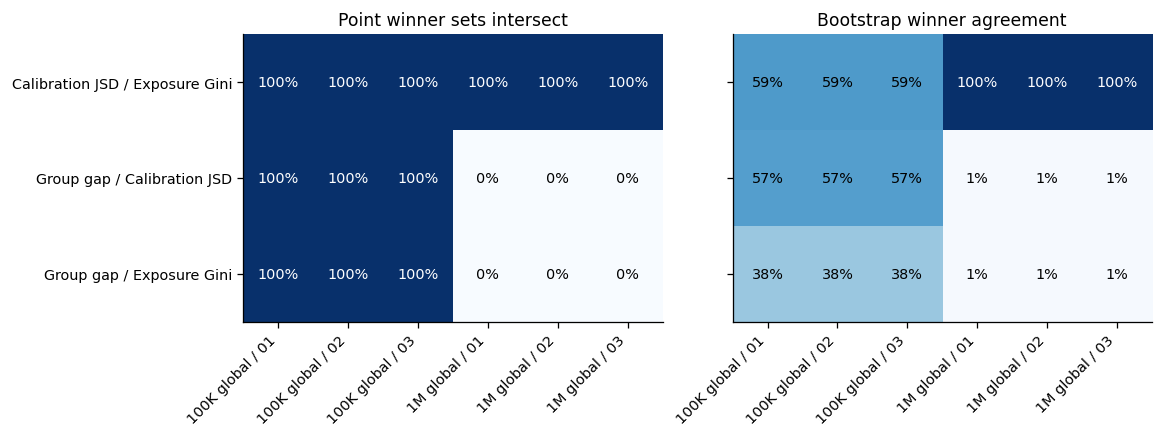

**Candidate winner support, complete draws and pairwise ordering retention** · 108 rows (first 25 shown)

,protocol,seed,depth,objective,candidate,point_winner,valid_draws,winner_support,nontied_candidate_pairs,mean_pair_sign_retention
12,100k,20261101,100,Group gap,Popularity__lambda_0.0,False,796,0.11181,5,0.7108
13,100k,20261101,100,Group gap,Popularity__lambda_0.1,False,796,0.11181,5,0.7108
14,100k,20261101,100,Group gap,Popularity__lambda_0.3,False,796,0.40578,5,0.7108
15,100k,20261101,100,Group gap,Popularity__lambda_0.5,True,796,0.56658,5,0.7108
16,100k,20261101,100,Calibration JSD,Popularity__lambda_0.0,False,1000,0.00000,6,1.0000
17,100k,20261101,100,Calibration JSD,Popularity__lambda_0.1,False,1000,0.00000,6,1.0000
18,100k,20261101,100,Calibration JSD,Popularity__lambda_0.3,False,1000,0.00000,6,1.0000
19,100k,20261101,100,Calibration JSD,Popularity__lambda_0.5,True,1000,1.00000,6,1.0000
20,100k,20261101,100,Exposure Gini,Popularity__lambda_0.0,False,1000,0.32700,6,0.7890
21,100k,20261101,100,Exposure Gini,Popularity__lambda_0.1,False,1000,0.08100,6,0.7890


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ1_T2_rank_and_winner_support.csv

**Three highest winner supports per objective, first fitting seed**

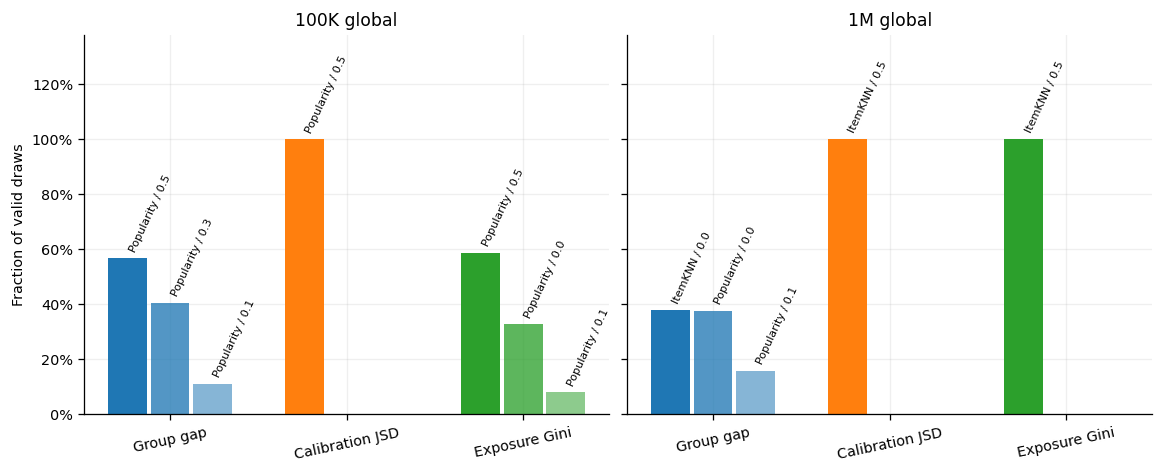

In [8]:
C1 = globals_only(base(CANDIDATES))
A1 = globals_only(base(AGREEMENT)).assign(pair=lambda t:t.objective_a+" / "+t.objective_b)
W1 = globals_only(base(WINNERS))
show_table(C1, "RQ1_T1_relevance_and_winners", "Validation relevance, eligibility and ties by configuration")
fig, axes = plt.subplots(1, 2, figsize=(10,3.7), layout="constrained")
xlabels = [f"{SHORT_PROTOCOL[t]} / {str(s)[-2:]}" for t,s in A1[["protocol","seed"]].drop_duplicates().itertuples(index=False)]
for ax,column,title in zip(axes,["point_agreement","draw_agreement_rate"],["Point winner sets intersect","Bootstrap winner agreement"]):
    z = A1.pivot(index="pair", columns=["protocol","seed"], values=column).astype(float)
    im = ax.imshow(z.to_numpy(),vmin=0,vmax=1,cmap="Blues",aspect="auto")
    ax.set_xticks(range(len(xlabels)), xlabels, rotation=45,ha="right")
    ax.set_yticks(range(len(z.index)),z.index if ax is axes[0] else [""]*len(z.index))
    ax.grid(False)
    ax.set_title(title)
    for (row,col),v in np.ndenumerate(z.to_numpy()):
        ax.text(col,row,f"{v:.0%}" if np.isfinite(v) else "N/E",ha="center",va="center",color="white" if v>.6 else "black")
show_figure(fig,"RQ1_F1_winner_agreement","Cross-objective winner agreement with unassessable comparisons marked")
show_table(W1, "RQ1_T2_rank_and_winner_support", "Candidate winner support, complete draws and pairwise ordering retention")
fig, axes = plt.subplots(1,2,figsize=(10,4),sharey=True,layout="constrained")
for ax,tag in zip(axes,GLOBAL):
    data = W1[(W1.protocol==tag)&(W1.seed==C.seeds[0])]
    for j,name in OBJECTIVES.items():
        values=data[data.objective==name].sort_values("winner_support",ascending=False).head(3)
        if not values.winner_support.notna().any():
            ax.text(j,0.08,"N/E",ha="center")
        for i,row in enumerate(values.itertuples()):
            if np.isfinite(row.winner_support):
                pos = j+(i-1)*.24
                ax.bar(pos,row.winner_support,width=.22,color=plt.get_cmap("tab10")(j-1),alpha=1-i*.23)
                if row.winner_support>0:
                    ax.text(pos,row.winner_support+.025,row.candidate.replace("__lambda_"," / "),rotation=65,fontsize=7)
    ax.set_xticks([1,2,3],list(OBJECTIVES.values()),rotation=12)
    ax.set_title(SHORT_PROTOCOL[tag])
    ax.set_ylim(0,1.38)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Fraction of valid draws")
show_figure(fig,"RQ1_F2_winner_support","Three highest winner supports per objective, first fitting seed")

## RQ2. Uncertainty and abstention

**All planned base versus reranker contrasts and simultaneous intervals** · 162 rows (first 25 shown)

,protocol,seed,depth,objective,base,reranker,validation_gain,val_low,val_high,test_gain,test_low,test_high,validation_evidence,apparent_improvement,estimated_sign_reversal,supported_sign_reversal
27,100k,20261101,100,Group gap,Popularity__lambda_0.0,Popularity__lambda_0.1,0.00000,-1.00000,1.00000,NaN,-1.00000,1.00000,Inconclusive,False,NaN,NaN
28,100k,20261101,100,Calibration JSD,Popularity__lambda_0.0,Popularity__lambda_0.1,0.00299,-0.51801,0.52399,0.00243,-0.75952,0.76439,Inconclusive,True,False,False
29,100k,20261101,100,Exposure Gini,Popularity__lambda_0.0,Popularity__lambda_0.1,-0.00002,-0.99936,0.99936,0.00003,-0.99936,0.99936,Inconclusive,False,True,False
30,100k,20261101,100,Group gap,Popularity__lambda_0.0,Popularity__lambda_0.3,0.00352,-1.00000,1.00000,NaN,-1.00000,1.00000,Inconclusive,True,NaN,NaN
31,100k,20261101,100,Calibration JSD,Popularity__lambda_0.0,Popularity__lambda_0.3,0.00978,-0.51122,0.53078,0.00970,-0.75225,0.77166,Inconclusive,True,False,False
32,100k,20261101,100,Exposure Gini,Popularity__lambda_0.0,Popularity__lambda_0.3,-0.00005,-0.99936,0.99936,0.00008,-0.99936,0.99936,Inconclusive,False,True,False
33,100k,20261101,100,Group gap,Popularity__lambda_0.0,Popularity__lambda_0.5,0.00518,-1.00000,1.00000,NaN,-1.00000,1.00000,Inconclusive,True,NaN,NaN
34,100k,20261101,100,Calibration JSD,Popularity__lambda_0.0,Popularity__lambda_0.5,0.02337,-0.49763,0.54437,0.02530,-0.73666,0.78726,Inconclusive,True,False,False
35,100k,20261101,100,Exposure Gini,Popularity__lambda_0.0,Popularity__lambda_0.5,0.00002,-0.99936,0.99936,0.00035,-0.99936,0.99936,Inconclusive,True,False,False
36,100k,20261101,100,Group gap,ItemKNN__lambda_0.0,ItemKNN__lambda_0.1,0.00000,-1.00000,1.00000,NaN,-1.00000,1.00000,Inconclusive,False,NaN,NaN


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ2_T1_contrasts_and_intervals.csv

**Validation evidence and later reversals with explicit denominators** · 18 rows (first 18 shown)

,protocol,seed,depth,objective,validation_evidence,contrasts,apparent_improvements,sign_assessable,estimated_reversals,supported_reversals
3,100k,20261101,100,Group gap,Inconclusive,9,5,0,0,0
4,100k,20261101,100,Calibration JSD,Inconclusive,9,9,9,0,0
5,100k,20261101,100,Exposure Gini,Inconclusive,9,7,9,2,0
12,100k,20261102,100,Group gap,Inconclusive,9,4,0,0,0
13,100k,20261102,100,Calibration JSD,Inconclusive,9,9,9,0,0
14,100k,20261102,100,Exposure Gini,Inconclusive,9,7,9,2,0
21,100k,20261103,100,Group gap,Inconclusive,9,4,0,0,0
22,100k,20261103,100,Calibration JSD,Inconclusive,9,9,9,0,0
23,100k,20261103,100,Exposure Gini,Inconclusive,9,7,9,2,0
30,1m,20261101,100,Group gap,Inconclusive,9,1,9,5,0


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ2_T2_evidence_and_reversals.csv

**Evidence classification across objectives, including unavailable contrasts**

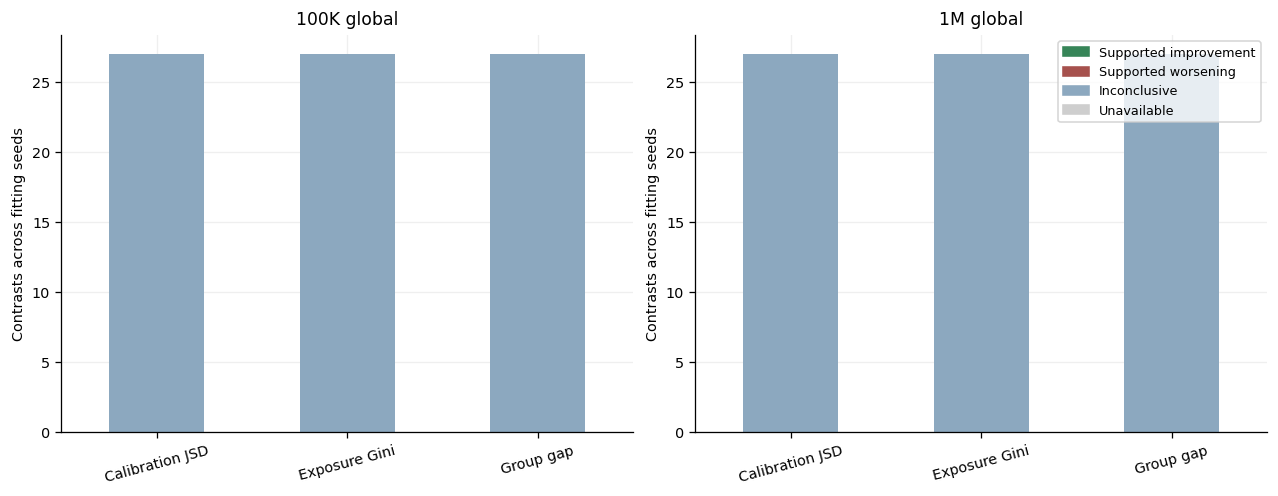

**Selection, threshold abstention and estimability failures by cutoff**

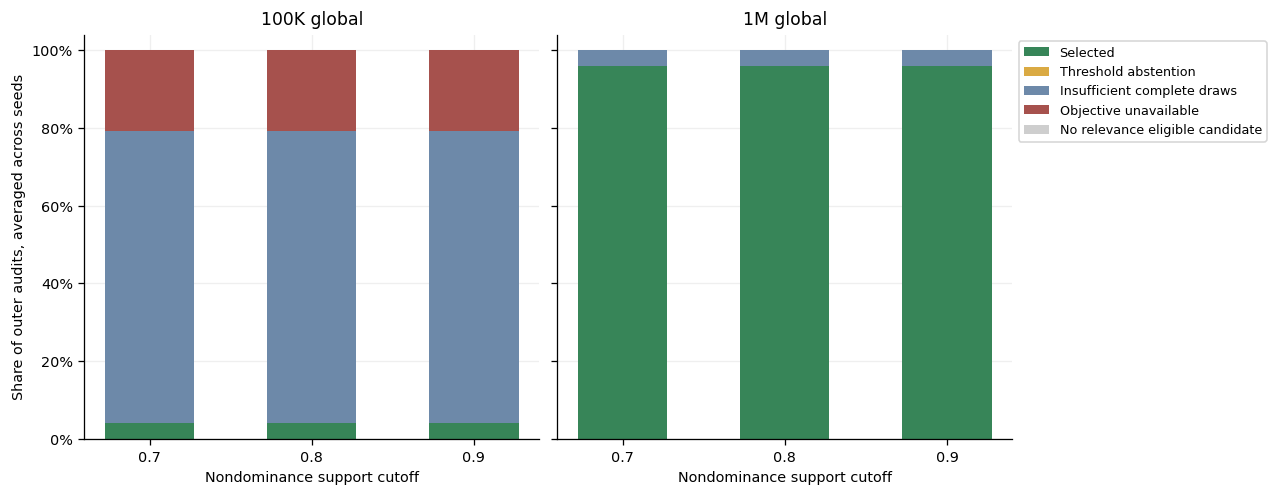

In [9]:
C2 = globals_only(base(CONTRAST))
T2 = globals_only(base(THRESH_SUMMARY)).query("scope == 'Three objectives'")
show_table(C2,"RQ2_T1_contrasts_and_intervals","All planned base versus reranker contrasts and simultaneous intervals")
show_table(globals_only(base(EVIDENCE)),"RQ2_T2_evidence_and_reversals",
    "Validation evidence and later reversals with explicit denominators")
fig,axes=plt.subplots(1,2,figsize=(11,4.2),layout="constrained")
evidence_colors={"Supported improvement":"#378558","Supported worsening":"#a6514d",
                 "Inconclusive":"#8ca8bf","Unavailable":"#cecece"}
for ax,tag in zip(axes,GLOBAL):
    d=C2[C2.protocol==tag]
    s=d.groupby(["objective","validation_evidence"]).size().unstack(fill_value=0)
    s.reindex(columns=evidence_colors,fill_value=0).plot.bar(ax=ax,stacked=True,legend=False,
        color=list(evidence_colors.values()),rot=15)
    ax.set_title(SHORT_PROTOCOL[tag])
    ax.set_xlabel("")
    ax.set_ylabel("Contrasts across fitting seeds")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=c,label=l) for l,c in evidence_colors.items()],fontsize=8)
show_figure(fig,"RQ2_F1_contrast_evidence","Evidence classification across objectives, including unavailable contrasts")
fig,axes=plt.subplots(1,2,figsize=(11,4.2),sharey=True,layout="constrained")
status_details={
    "selected_share":("Selected","#378558"),
    "threshold_abstention_share":("Threshold abstention","#daaa43"),
    "incomplete_draw_share":("Insufficient complete draws","#6d89a9"),
    "missing_objective_share":("Objective unavailable","#a6514d"),
    "no_eligible_share":("No relevance eligible candidate","#cecece")}
for ax,tag in zip(axes,GLOBAL):
    data=T2[T2.protocol==tag].groupby("cutoff")[list(status_details)].mean()
    bottom=np.zeros(len(data))
    for status,(label,color) in status_details.items():
        ax.bar(data.index,data[status],bottom=bottom,width=.055,label=label,color=color)
        bottom+=data[status].to_numpy()
    ax.set(xticks=C.thresholds,ylim=(0,1.04),title=SHORT_PROTOCOL[tag],xlabel="Nondominance support cutoff")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Share of outer audits, averaged across seeds")
axes[1].legend(fontsize=8,loc="upper left",bbox_to_anchor=(1,1))
show_figure(fig,"RQ2_F2_decisions_by_cutoff","Selection, threshold abstention and estimability failures by cutoff")

## RQ3. Shortlist trade-offs

**Selector scorecard with audit, overlap and later quality denominators** · 48 rows (first 25 shown)

,protocol,seed,depth,scope,rule,audits,outer_sample_size,mean_size,empty_rate,overlap_pairs,both_empty_pairs,mean_union_overlap,mean_nonempty_overlap,frontier_estimable,later_dominated_estimable,later_relevance_loss_estimable,mean_later_frontier_recall,mean_later_dominated,median_later_relevance_loss
8,100k,20261101,100,Three objectives,Bootstrap Pareto,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00072
9,100k,20261101,100,Three objectives,Point Pareto,24,77,1.16667,0.20833,266,10,0.24060,0.37427,0,0,19,NaN,NaN,0.00036
10,100k,20261101,100,Three objectives,Single gap,24,77,0.79167,0.20833,266,10,0.22180,0.34503,0,0,19,NaN,NaN,0.00000
11,100k,20261101,100,Three objectives,Single calibration,24,77,1.00000,0.00000,276,0,0.57609,0.57609,0,0,24,NaN,NaN,0.00000
12,100k,20261101,100,Three objectives,Single exposure,24,77,1.00000,0.00000,276,0,0.37319,0.37319,0,0,24,NaN,NaN,0.00000
13,100k,20261101,100,Three objectives,Top relevance,24,77,1.00000,0.00000,276,0,0.36232,0.36232,0,0,24,NaN,NaN,0.02472
14,100k,20261101,100,Three objectives,Size-matched random,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00072
15,100k,20261101,100,Three objectives,Size-matched relevance,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00000
39,100k,20261102,100,Three objectives,Bootstrap Pareto,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00072
40,100k,20261102,100,Three objectives,Point Pareto,24,77,1.16667,0.20833,266,10,0.20677,0.32164,0,0,19,NaN,NaN,0.00037


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ3_T1_selector_scorecard.csv

**Within-audit bootstrap minus comparator differences and interquartile ranges** · 168 rows (first 25 shown)

,protocol,seed,depth,scope,control,measure,paired_audits,median_difference,mean_difference,q25,q75
28,100k,20261101,100,Three objectives,Point Pareto,size,24,-1.00000,-1.12500,-2.00000,-0.75000
29,100k,20261101,100,Three objectives,Point Pareto,test_frontier_recall,0,NaN,NaN,NaN,NaN
30,100k,20261101,100,Three objectives,Point Pareto,test_dominated,0,NaN,NaN,NaN,NaN
31,100k,20261101,100,Three objectives,Point Pareto,median_test_relevance_loss,1,0.00000,0.00000,0.00000,0.00000
32,100k,20261101,100,Three objectives,Single gap,size,24,-1.00000,-0.75000,-1.00000,-0.75000
33,100k,20261101,100,Three objectives,Single gap,test_frontier_recall,0,NaN,NaN,NaN,NaN
34,100k,20261101,100,Three objectives,Single gap,test_dominated,0,NaN,NaN,NaN,NaN
35,100k,20261101,100,Three objectives,Single gap,median_test_relevance_loss,1,0.00072,0.00072,0.00072,0.00072
36,100k,20261101,100,Three objectives,Single calibration,size,24,-1.00000,-0.95833,-1.00000,-1.00000
37,100k,20261101,100,Three objectives,Single calibration,test_frontier_recall,0,NaN,NaN,NaN,NaN


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ3_T2_paired_control_differences.csv

**Stability against shortlist size, one point per fitting seed**

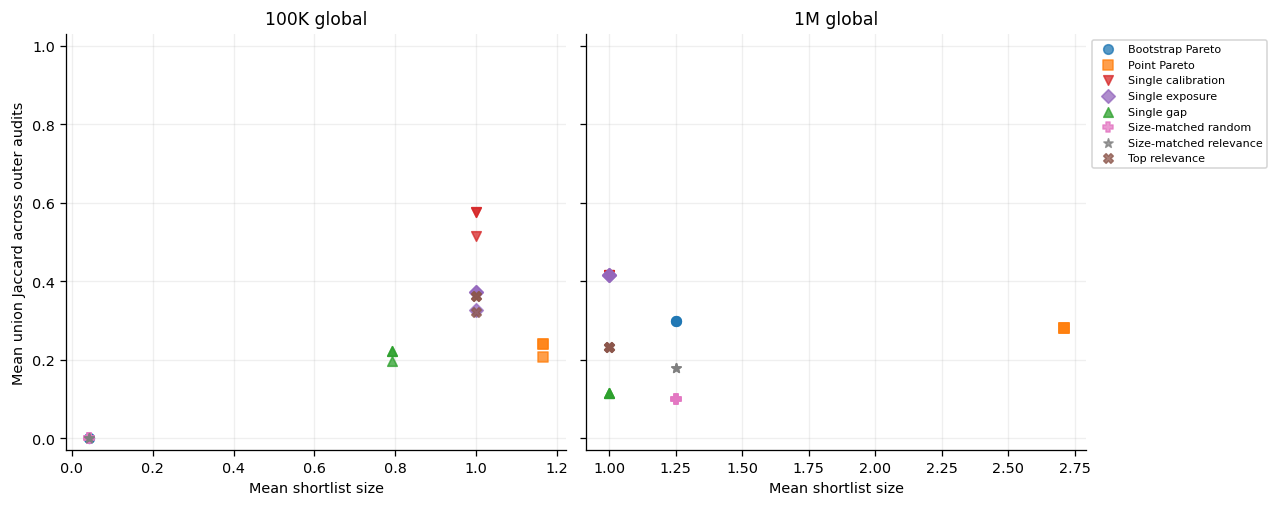

**Later-frontier coverage and dominated selections in the frozen validation pool**

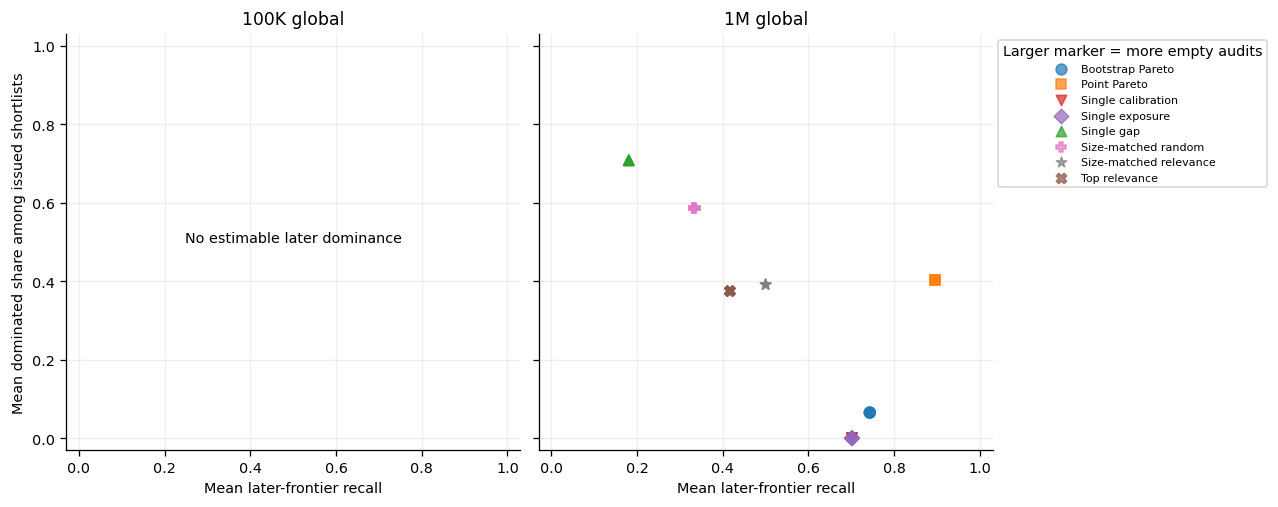

In [10]:
S3=globals_only(base(SELECTOR)).query("scope == 'Three objectives'")
M3=globals_only(base(MATCHED)).query("scope == 'Three objectives'")
show_table(S3,"RQ3_T1_selector_scorecard","Selector scorecard with audit, overlap and later quality denominators")
show_table(M3,"RQ3_T2_paired_control_differences","Within-audit bootstrap minus comparator differences and interquartile ranges")
fig,axes=plt.subplots(1,2,figsize=(11,4.3),sharey=True,layout="constrained")
for ax,tag in zip(axes,GLOBAL):
    data=S3[S3.protocol==tag]
    for rule,g in data.groupby("rule"):
        ax.scatter(g.mean_size,g.mean_union_overlap,label=rule,color=PALETTE[rule],marker=MARKERS[rule],alpha=.75)
    ax.set(title=SHORT_PROTOCOL[tag],xlabel="Mean shortlist size",ylim=(-.03,1.03))
axes[0].set_ylabel("Mean union Jaccard across outer audits")
axes[1].legend(fontsize=7,loc="upper left",bbox_to_anchor=(1,1))
show_figure(fig,"RQ3_F1_stability_and_selectivity","Stability against shortlist size, one point per fitting seed")
fig,axes=plt.subplots(1,2,figsize=(11,4.3),sharey=True,layout="constrained")
for ax,tag in zip(axes,GLOBAL):
    data=S3[S3.protocol==tag]
    if not data.mean_later_dominated.notna().any():
        ax.text(.5,.5,"No estimable later dominance",ha="center",transform=ax.transAxes)
    for rule,g in data.groupby("rule"):
        ax.scatter(g.mean_later_frontier_recall,g.mean_later_dominated,
                   s=42+100*g.empty_rate,label=rule,color=PALETTE[rule],marker=MARKERS[rule],alpha=.7)
    ax.set(title=SHORT_PROTOCOL[tag],xlabel="Mean later-frontier recall",xlim=(-.03,1.03),ylim=(-.03,1.03))
axes[0].set_ylabel("Mean dominated share among issued shortlists")
axes[1].legend(fontsize=7,loc="upper left",bbox_to_anchor=(1,1),title="Larger marker = more empty audits")
show_figure(fig,"RQ3_F2_later_frontier_tradeoff","Later-frontier coverage and dominated selections in the frozen validation pool")

## RQ4. Coverage and candidate depth

The supplementary top-10 diagnostic compares the final recommendations at each alternative depth with depth 100 in the full run, for the same eligible users, period, fitted seed and candidate configuration in the global MovieLens protocols. It distinguishes identical ordered lists, changes in order alone, and changes in item membership. The summary counts user-list pairs across candidate configurations and seeds. A user can contribute multiple pairs.

**Observed and eligible demographic groups by period, including intersections** · 138 rows (first 25 shown)

,protocol,window,attribute,group,observed_users,eligible_users,otherwise_eligible_reserved_for_tuning,inclusion_rate,below_reporting_threshold
0,100k,val,gender,F,66,14,6,0.21212,True
1,100k,val,gender,M,181,63,20,0.34807,False
2,100k,val,age,1,10,3,0,0.30000,True
3,100k,val,age,18,63,19,4,0.30159,True
4,100k,val,age,25,83,29,7,0.34940,True
5,100k,val,age,35,39,12,8,0.30769,True
6,100k,val,age,45,24,9,3,0.37500,True
7,100k,val,age,50,18,2,3,0.11111,True
8,100k,val,age,56,10,3,1,0.30000,True
9,100k,val,age_by_gender,"(1, 'F')",4,0,0,0.00000,True


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ4_T1_demographic_coverage.csv

**RQ1–RQ3 changes against the reference retrieval depth** · 18 rows (first 18 shown)

,protocol,seed,depth,reference_depth,assessable_objective_pairs,change_mean_pair_winner_agreement,supported_improvements,change_supported_improvements,proportion_pools_changed,same_audit_overlap,overlap_estimable,change_empty_rate,change_mean_size,change_union_overlap,change_later_dominated,change_later_frontier_recall,change_median_later_relevance_loss
0,100k,20261101,50,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
1,100k,20261101,100,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
2,100k,20261101,200,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
3,100k,20261102,50,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
4,100k,20261102,100,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
5,100k,20261102,200,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
6,100k,20261103,50,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
7,100k,20261103,100,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
8,100k,20261103,200,100,3,0.0,0,0,0.0,1.0,1,0.0,0.0,0.0,NaN,NaN,0.0
9,1m,20261101,50,100,3,0.0,0,0,0.0,1.0,23,0.0,0.0,0.0,0.0,0.0,0.0


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ4_T2_paired_depth_sensitivity.csv

**Supplementary RQ4 diagnostic · changes in the final top-10 lists**

,protocol,window,depth,reference_depth,comparison_cells,user_list_pairs,unchanged_top10,order_only_changed,items_changed,any_change,any_change_rate
0,100k,test,50,100,36,1296,1296,0,0,0,0.0
1,100k,test,200,100,36,1296,1296,0,0,0,0.0
2,100k,val,50,100,36,2772,2772,0,0,0,0.0
3,100k,val,200,100,36,2772,2772,0,0,0,0.0
4,1m,test,50,100,36,12636,12636,0,0,0,0.0
5,1m,test,200,100,36,12636,12636,0,0,0,0.0
6,1m,val,50,100,36,6552,6552,0,0,0,0.0
7,1m,val,200,100,36,6552,6552,0,0,0,0.0


/kaggle/working/Project9_full_20261125T102615Z_4e6106/diagnostics/top10_depth_comparison.csv

/kaggle/working/Project9_full_20261125T102615Z_4e6106/diagnostics/top10_depth_summary.csv

**Group completeness by demographic definition, with smallest cell counts**

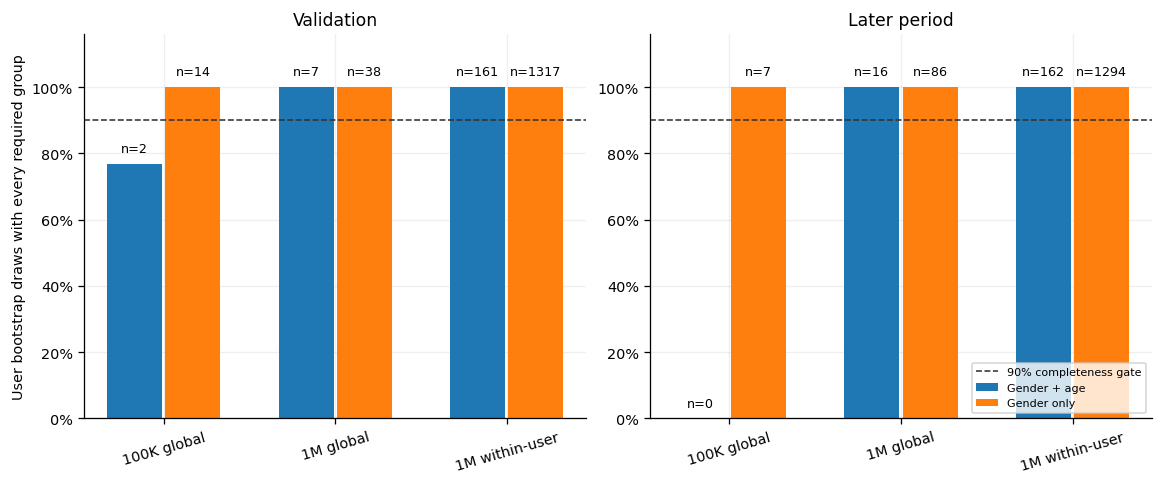

**Candidate recall across depths, with ranges over fitting seeds**

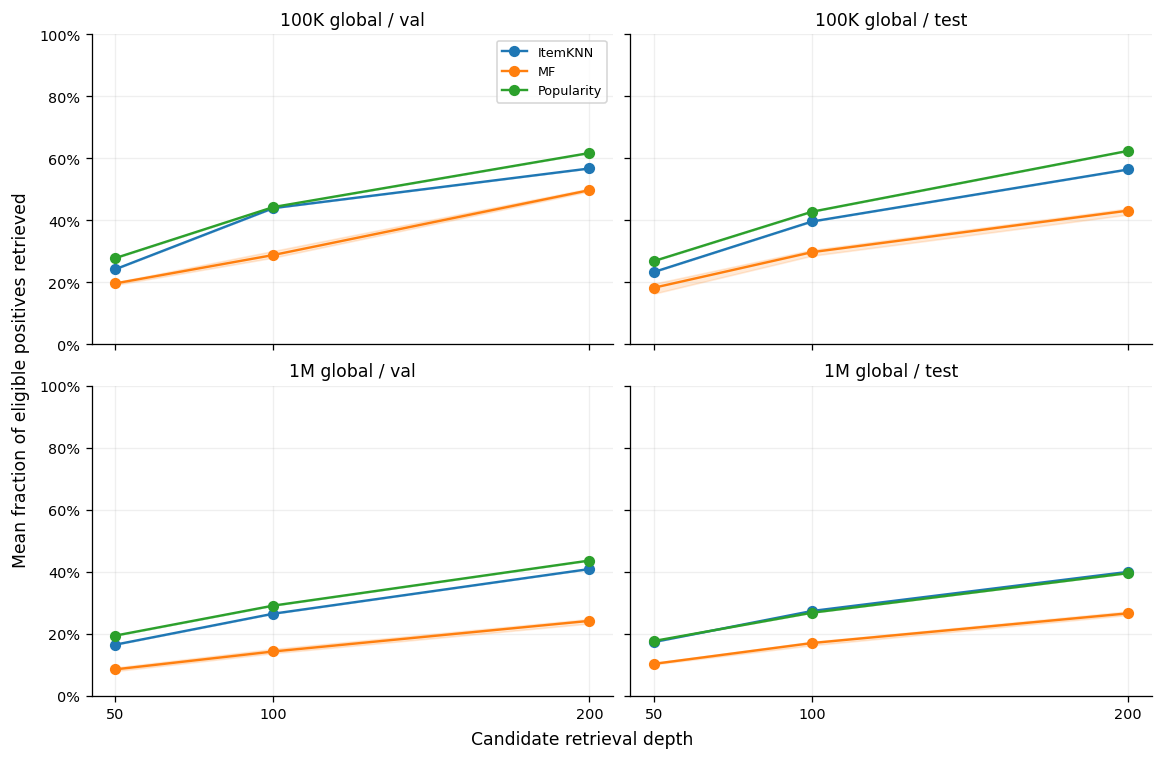

In [11]:
G4=GROUP.copy()
B4=base(COVERAGE).drop_duplicates(["protocol","window","grouping"])
show_table(G4,"RQ4_T1_demographic_coverage","Observed and eligible demographic groups by period, including intersections")
show_table(DEPTH,"RQ4_T2_paired_depth_sensitivity","RQ1–RQ3 changes against the reference retrieval depth")

display(Markdown("**Supplementary RQ4 diagnostic · changes in the final top-10 lists**"))
display(TOP10_SUMMARY.round(5))
for filename in ("top10_depth_comparison.csv", "top10_depth_summary.csv"):
    display(FileLink(os.path.relpath(ROOT / "diagnostics" / filename, Path.cwd())))
fig,axes=plt.subplots(1,2,figsize=(10,4.1),layout="constrained")
for ax,(window,g) in zip(axes,B4.groupby("window",sort=False)):
    x=np.arange(g.protocol.nunique())
    labels=[SHORT_PROTOCOL[t] for t in g.protocol.unique()]
    for i,(grouping,rows) in enumerate(g.groupby("grouping",sort=False)):
        xpos=x+(i-.5)*.34
        ax.bar(xpos,rows.complete_draw_fraction,width=.32,label=grouping)
        for pos,row in zip(xpos,rows.itertuples()):
            ax.text(pos,row.complete_draw_fraction+.035,f"n={row.smallest_cell}",rotation=0,ha="center",fontsize=8)
    ax.axhline(.9,ls="--",color="#333",lw=1,label="90% completeness gate")
    ax.set(xticks=x,xticklabels=labels,ylim=(0,1.16),title={"val":"Validation","test":"Later period"}[window])
    ax.tick_params(axis="x",rotation=16)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("User bootstrap draws with every required group")
axes[1].legend(fontsize=7,loc="lower right")
show_figure(fig,"RQ4_F1_group_estimability","Group completeness by demographic definition, with smallest cell counts")
fig,axes=plt.subplots(2,2,figsize=(10,6.5),sharex=True,sharey=True,layout="constrained")
for ax,(tag,window) in zip(axes.flat,[(t,w) for t in GLOBAL for w in ["val","test"]]):
    data=RECALL[(RECALL.protocol==tag)&(RECALL.window==window)]
    for model,g in data.groupby("model"):
        s=g.groupby("depth").mean_recall.agg(["mean","min","max"]).sort_index()
        color=ax.plot(s.index,s["mean"],"o-",label=model)[0].get_color()
        ax.fill_between(s.index.to_numpy(),s["min"].to_numpy(),s["max"].to_numpy(),color=color,alpha=.16)
    ax.set(title=f"{SHORT_PROTOCOL[tag]} / {window}",xticks=C.depths,ylim=(0,1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0,0].legend(fontsize=8)
fig.supxlabel("Candidate retrieval depth")
fig.supylabel("Mean fraction of eligible positives retrieved")
show_figure(fig,"RQ4_F2_candidate_recall","Candidate recall across depths, with ranges over fitting seeds")

## RQ5. Scope of transfer

**Cohort sizes, chronology and admissible fairness objectives** · 12 rows (first 12 shown)

,protocol,split,window,observed_users,eligible_users,events,unseen_catalogue_events,catalogue,start_utc,end_utc,demographic_gap_available_in_scope,calibration_feature
0,100k,global_chronological,tune,247,26,14999,217,1573,1998-02-09 15:48:49+00:00,1998-03-27 22:06:54+00:00,True,movie genres
1,100k,global_chronological,val,247,77,14999,217,1573,1998-02-09 15:48:49+00:00,1998-03-27 22:06:54+00:00,True,movie genres
2,100k,global_chronological,test,226,36,15000,333,1573,1998-03-27 22:07:03+00:00,1998-04-22 23:10:38+00:00,True,movie genres
3,1m,global_chronological,tune,663,52,72517,66,3503,2000-11-22 03:06:33+00:00,2000-12-10 03:50:50+00:00,True,movie genres
4,1m,global_chronological,val,663,182,72517,66,3503,2000-11-22 03:06:33+00:00,2000-12-10 03:50:50+00:00,True,movie genres
5,1m,global_chronological,test,752,351,74585,120,3503,2000-12-10 04:22:45+00:00,2003-02-28 17:49:50+00:00,True,movie genres
6,1m_userchron,within_user_chronological,tune,5959,1175,148679,27,3652,2000-04-25 23:40:19+00:00,2003-02-24 20:26:20+00:00,True,movie genres
7,1m_userchron,within_user_chronological,val,5959,4646,148679,27,3652,2000-04-25 23:40:19+00:00,2003-02-24 20:26:20+00:00,True,movie genres
8,1m_userchron,within_user_chronological,test,5918,4582,142981,50,3652,2000-04-25 23:43:21+00:00,2003-02-28 17:49:50+00:00,True,movie genres
9,lastfm_tag,global_chronological,tune,494,42,4109,0,1000,2010-02-28 23:00:00+00:00,2010-07-31 22:00:00+00:00,False,artist tags


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ5_T1_protocol_scope.csv

**Selector outcomes by protocol and objective set, with a common calibration/exposure comparison** · 156 rows (first 25 shown)

,protocol,seed,depth,scope,rule,audits,outer_sample_size,mean_size,empty_rate,overlap_pairs,both_empty_pairs,mean_union_overlap,mean_nonempty_overlap,frontier_estimable,later_dominated_estimable,later_relevance_loss_estimable,mean_later_frontier_recall,mean_later_dominated,median_later_relevance_loss
8,100k,20261101,100,Three objectives,Bootstrap Pareto,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00072
9,100k,20261101,100,Three objectives,Point Pareto,24,77,1.16667,0.20833,266,10,0.24060,0.37427,0,0,19,NaN,NaN,0.00036
10,100k,20261101,100,Three objectives,Single gap,24,77,0.79167,0.20833,266,10,0.22180,0.34503,0,0,19,NaN,NaN,0.00000
11,100k,20261101,100,Three objectives,Single calibration,24,77,1.00000,0.00000,276,0,0.57609,0.57609,0,0,24,NaN,NaN,0.00000
12,100k,20261101,100,Three objectives,Single exposure,24,77,1.00000,0.00000,276,0,0.37319,0.37319,0,0,24,NaN,NaN,0.00000
13,100k,20261101,100,Three objectives,Top relevance,24,77,1.00000,0.00000,276,0,0.36232,0.36232,0,0,24,NaN,NaN,0.02472
14,100k,20261101,100,Three objectives,Size-matched random,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00072
15,100k,20261101,100,Three objectives,Size-matched relevance,24,77,0.04167,0.95833,23,253,0.00000,NaN,0,0,1,NaN,NaN,0.00000
16,100k,20261101,100,Calibration + exposure,Bootstrap Pareto,24,77,1.04167,0.00000,276,0,0.57609,0.57609,24,24,24,1.00000,0.02083,0.00000
17,100k,20261101,100,Calibration + exposure,Point Pareto,24,77,1.29167,0.00000,276,0,0.47222,0.47222,24,24,24,1.00000,0.14583,0.00000


/kaggle/working/Project9_full_20261125T102615Z_4e6106/tables/RQ5_T2_cross_protocol_selectors.csv

**Calibration versus exposure winner agreement, with one point per fitting seed**

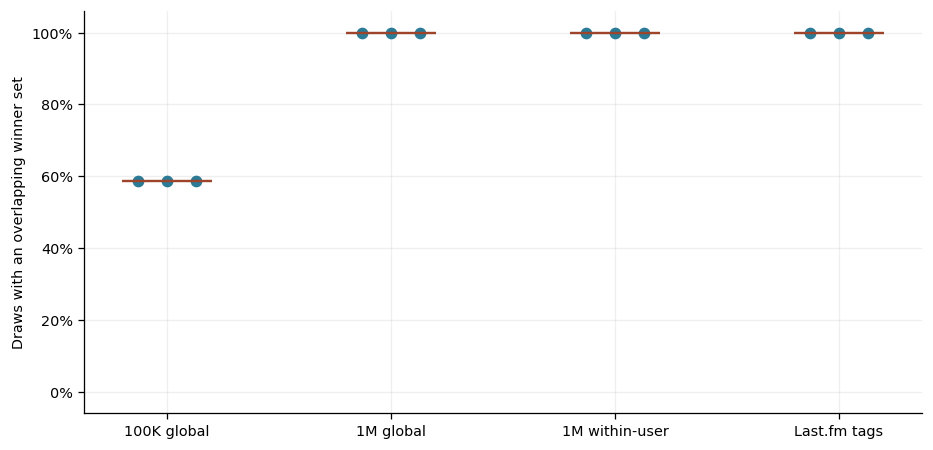

**Retrospective set overlap and frontier coverage on shared objectives**

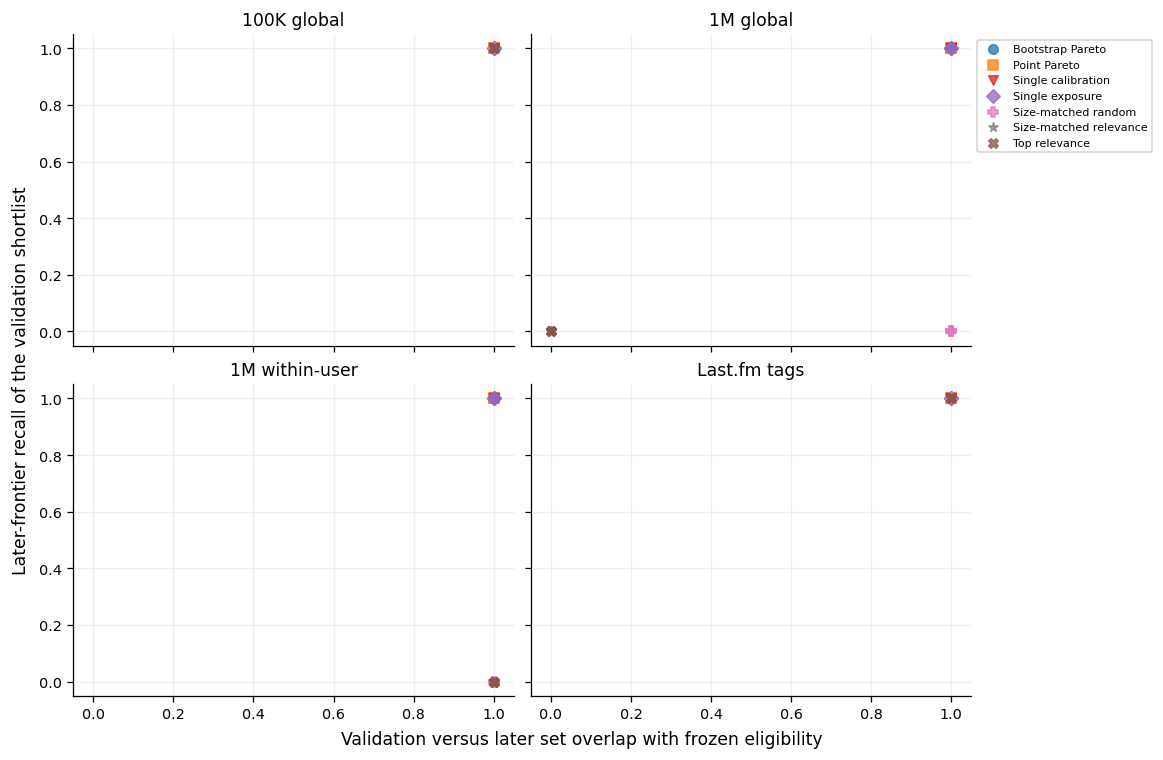

,protocol,seed,depth,scope,rule,audits,outer_sample_size,mean_size,empty_rate,overlap_pairs,both_empty_pairs,mean_union_overlap,mean_nonempty_overlap,frontier_estimable,later_dominated_estimable,later_relevance_loss_estimable,mean_later_frontier_recall,mean_later_dominated,median_later_relevance_loss
0,100k,20261101,50,Three objectives,Bootstrap Pareto,24,77,0.041667,0.958333,23,253,0.000000,NaN,0,0,1,NaN,NaN,0.000725
1,100k,20261101,50,Three objectives,Point Pareto,24,77,1.166667,0.208333,266,10,0.240602,0.374269,0,0,19,NaN,NaN,0.000362
2,100k,20261101,50,Three objectives,Single gap,24,77,0.791667,0.208333,266,10,0.221805,0.345029,0,0,19,NaN,NaN,0.000000
3,100k,20261101,50,Three objectives,Single calibration,24,77,1.000000,0.000000,276,0,0.576087,0.576087,0,0,24,NaN,NaN,0.000000
4,100k,20261101,50,Three objectives,Single exposure,24,77,1.000000,0.000000,276,0,0.373188,0.373188,0,0,24,NaN,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,lastfm_tag,20261103,100,Calibration + exposure,Single calibration,24,155,1.000000,0.000000,276,0,1.000000,1.000000,24,24,24,1.000000,0.000000,0.000000
248,lastfm_tag,20261103,100,Calibration + exposure,Single exposure,24,155,1.000000,0.000000,276,0,0.579710,0.579710,24,24,24,0.750000,0.250000,0.000000
249,lastfm_tag,20261103,100,Calibration + exposure,Top relevance,24,155,1.000000,0.000000,276,0,1.000000,1.000000,24,24,24,1.000000,0.000000,0.000000
250,lastfm_tag,20261103,100,Calibration + exposure,Size-matched random,24,155,1.333333,0.000000,276,0,0.745471,0.745471,24,24,24,0.958333,0.142361,0.000000


In [12]:
S5=base(SELECTOR)
A5=base(AGREEMENT).query("objective_a == 'Calibration JSD' and objective_b == 'Exposure Gini'")
T5=base(TEMPORAL).query("scope == 'Calibration + exposure'")
show_table(SCOPE,"RQ5_T1_protocol_scope","Cohort sizes, chronology and admissible fairness objectives")
show_table(S5,"RQ5_T2_cross_protocol_selectors","Selector outcomes by protocol and objective set, with a common calibration/exposure comparison")
fig,ax=plt.subplots(figsize=(8,3.8),layout="constrained")
for i,tag in enumerate(PROTOCOLS):
    data=A5[A5.protocol==tag]
    values=data.draw_agreement_rate
    pos=i+np.linspace(-.13,.13,len(values))
    ax.scatter(pos,values,s=40,color="#2b7a96")
    ax.hlines(values.mean(),i-.20,i+.20,color="#9d442a")
    if not values.notna().any():
        ax.text(i,.03,"N/E",ha="center")
ax.set(xticks=range(len(PROTOCOLS)),xticklabels=[SHORT_PROTOCOL[t] for t in PROTOCOLS],
       ylim=(-.06,1.06),ylabel="Draws with an overlapping winner set")
ax.yaxis.set_major_formatter(PercentFormatter(1))
show_figure(fig,"RQ5_F1_shared_objective_agreement","Calibration versus exposure winner agreement, with one point per fitting seed")
fig,axes=plt.subplots(2,2,figsize=(10,6.5),sharex=True,sharey=True,layout="constrained")
for ax,tag in zip(axes.flat,PROTOCOLS):
    pane=T5[T5.protocol==tag]
    for rule,g in pane.groupby("rule"):
        ax.scatter(g.later_overlap,g.test_frontier_recall,label=rule,color=PALETTE[rule],
                   marker=MARKERS[rule],alpha=.75)
    ax.set(title=SHORT_PROTOCOL[tag],xlim=(-.05,1.05),ylim=(-.05,1.05))
axes[0,1].legend(fontsize=7,loc="upper left",bbox_to_anchor=(1,1))
fig.supxlabel("Validation versus later set overlap with frozen eligibility")
fig.supylabel("Later-frontier recall of the validation shortlist")
show_figure(fig,"RQ5_F2_later_selection_transfer","Retrospective set overlap and frontier coverage on shared objectives")
table(GROUP,"demographic_groups")
table(COVERAGE,"coverage_by_group_definition")
table(THRESH_SUMMARY,"threshold_summary")
table(SELECTOR,"selector_scorecard")

## Verify and export the results

In [13]:
inventory = pd.DataFrame(EXHIBITS,columns=["id","format","title","path"])
assert len(inventory)==20 and inventory.id.is_unique and inventory.path.is_unique
assert (inventory.groupby(inventory.id.str[:3]).size() == 4).all()
assert inventory.format.value_counts().to_dict() == {"CSV":10,"PDF":10}
for row in inventory.itertuples():
    path=ROOT/row.path
    if row.format=="CSV":
        assert len(pd.read_csv(path).columns)>0
    else:
        assert path.read_bytes().startswith(b"%PDF-")
inventory.to_csv(ROOT/"manifest"/"exhibit_inventory.csv",index=False)
write_json("run_status",dict(completed=True,mode=MODE,pdf_figures=10,csv_exhibits=10,
    elapsed_seconds=time.perf_counter()-START,protocols=PROTOCOLS,
    top10_depth_comparison_rows=len(TOP10), top10_depth_summary_rows=len(TOP10_SUMMARY),
    top10_depth_outputs=["diagnostics/top10_depth_comparison.csv",
                         "diagnostics/top10_depth_summary.csv"]))
paths=sorted(p for p in ROOT.rglob("*") if p.is_file())
write_json("checksums",[dict(path=str(p.relative_to(ROOT)),sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in paths])
bundle=ROOT.with_suffix(".zip")
with zipfile.ZipFile(bundle,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(ROOT.rglob("*")):
        if p.is_file():
            z.write(p,p.relative_to(ROOT.parent))
with zipfile.ZipFile(bundle) as z:
    assert z.testzip() is None
display(inventory)
print(f"Completed {MODE} run in {(time.perf_counter()-START)/60:.1f} minutes.")
display(FileLink(os.path.relpath(bundle,Path.cwd())))
print(bundle)

,id,format,title,path
0,RQ1_T1_relevance_and_winners,CSV,"Validation relevance, eligibility and ties by ...",tables/RQ1_T1_relevance_and_winners.csv
1,RQ1_F1_winner_agreement,PDF,Cross-objective winner agreement with unassess...,figures/RQ1_F1_winner_agreement.pdf
2,RQ1_T2_rank_and_winner_support,CSV,"Candidate winner support, complete draws and p...",tables/RQ1_T2_rank_and_winner_support.csv
3,RQ1_F2_winner_support,PDF,"Three highest winner supports per objective, f...",figures/RQ1_F2_winner_support.pdf
4,RQ2_T1_contrasts_and_intervals,CSV,All planned base versus reranker contrasts and...,tables/RQ2_T1_contrasts_and_intervals.csv
5,RQ2_T2_evidence_and_reversals,CSV,Validation evidence and later reversals with e...,tables/RQ2_T2_evidence_and_reversals.csv
6,RQ2_F1_contrast_evidence,PDF,"Evidence classification across objectives, inc...",figures/RQ2_F1_contrast_evidence.pdf
7,RQ2_F2_decisions_by_cutoff,PDF,"Selection, threshold abstention and estimabili...",figures/RQ2_F2_decisions_by_cutoff.pdf
8,RQ3_T1_selector_scorecard,CSV,"Selector scorecard with audit, overlap and lat...",tables/RQ3_T1_selector_scorecard.csv
9,RQ3_T2_paired_control_differences,CSV,Within-audit bootstrap minus comparator differ...,tables/RQ3_T2_paired_control_differences.csv


Completed full run in 6.7 minutes.


/kaggle/working/Project9_full_20261125T102615Z_4e6106.zip

/kaggle/working/Project9_full_20261125T102615Z_4e6106.zip


## Source code license

Inherited notebook components come from the original MIT-licensed Project 9 artifact.

```text
MIT License

Copyright (c) 2026 Cosmicrider1166

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```